# Heartsteps Matrix Completion using Nearest Neighbor Strategies

## Motivation

Within many real-world applications, there is an interest in measuring reaction to stimuli over time. For example, in a medical trial for a new drug, participants might receive dosages at various times over the trial period. This yields a unique structure of data, where patients (units) receive drug dosages (treatments) at certain times (decision points) while being monitored in between dosages for changes in health condition (outcomes). 

Consider a more general case: there are $N$ units who undergo $T$ potential treatment periods. At treatment period $t$, a unit $i$ receives treatment if $A_{i, t} = 1$ and does not if $A_{i, t} = 0$. Suppose for each combination of unit $i$ and treatment period $T$, there are $n$ measurements of the characteristics of unit $i$ at this treatment period. We denote these measurements as $X_k(i, t) \in \mathbb{R}^d$ for $k \in [n]$. Each $X_k(i, t)$ is sampled from a unit-treatment period specific distribution $\mu_{i, t}$. To estimate the effect of the treatment strategy across $T$ periods at a unit-treatment level of specificity, we must consider the counterfactuals: the measurements $X_k(i, t)$ such that the treatment $A_{i, t}$ is the opposite of what was observed.

To be continued...

## Structure

We make the assumption that the data is stored in a format similar to the Heartsteps dataset shown below. Each row represents a user and a segment of time (in the Heartsteps case, every 5 minutes from 9:05am-9:00pm). Each row indicates the outcome of interest and whether or not the treatment was applied during that measurement time. 

`transfom_dnn` takes in data formatted like this and transforms it into usable arrays that match the problem description above. More specifically, it creates 2 matrices, $A$ and $M$ both of size $N$ x $T$. As above, $A$ is the treatment matrix, where $A_{ij} = 1$ when unit $i$ received the treatment at treatment period $j$ and $A_{ij} = 0$ otherwise. The Heartsteps data extends this idea to multiple treatments, which we dicuss below. Each entry of $M$ is an array of length $n$ that contains measurements $X_k(i, j) \in \mathbb{R}^d$ for $k \in [n]$ that represent the outcome of interest.  

### Heartsteps Specific Structure

For the Heartsteps data used as a primary example below, we have 37 study participants (units) and ~6 weeks long trials. Various users had interruptions in their data collection that shortened their trial periods. The data we use is user step count at 5 minute intervals for the entire trial period. Time periods are denoted as a collection of these 5 minute intervals and is an important parameter to discuss for model performance. A user $i$ at time period $j$ is in 1 of 3 treatment scenarios: $A_{i, j} = 0$ when they do not receive a notification treatment and are available, $A_{i, j} = 1$ when they do receive a notification treatment, and $A_{i, j} = 2$ when they are available. Users do not receive notifications if they are unavailable. 

More on study structure?

## Data

In [6]:
import numpy as np
import pandas as pd
from itertools import chain
import itertools
import datetime
from matplotlib.pyplot import matshow
import matplotlib.pyplot as plt
import math

In [3]:
# read in Heartsteps dataset
df_hs = pd.read_csv("data_use.csv")
df_hs

,user.index,date,time,5min_datetime,steps,rolling_sum,rt,sugg.decision.5min,send.sedentary,availability
0,1,7/22/2015,9:05:00,NaN,0,0,1,NaN,0,1
1,1,7/22/2015,9:10:00,NaN,0,0,1,NaN,0,1
2,1,7/22/2015,9:15:00,NaN,0,0,1,NaN,0,1
3,1,7/22/2015,9:20:00,NaN,0,0,1,NaN,0,1
4,1,7/22/2015,9:25:00,NaN,0,0,1,NaN,0,1
...,...,...,...,...,...,...,...,...,...,...
228235,37,1/26/2016,20:40:00,NaN,0,0,1,NaN,0,1
228236,37,1/26/2016,20:45:00,NaN,0,0,1,NaN,0,1
228237,37,1/26/2016,20:50:00,NaN,0,0,1,NaN,0,1
228238,37,1/26/2016,20:55:00,NaN,0,0,1,NaN,0,1


In [13]:
# treatment is 0 if not sent, 1 if sent, and 2 if not available
df_hs['treatment'] = 0
df_hs['treatment'][df_hs['availability'] == 0] = 2
df_hs['treatment'][df_hs['send.sedentary'] == 1] = 1

C:\Users\Caleb\AppData\Local\Temp\ipykernel_19552\3500485869.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_hs['treatment'][df_hs['availability'] == 0] = 2
C:\Users\Caleb\AppData\Local\Temp\ipykernel_19552\3500485869.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_hs['treatment'][df_hs['send.sedentary'] == 1] = 1


C:\Users\Caleb\AppData\Local\Temp\ipykernel_19552\98446096.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_time_ind["date"] = pd.to_datetime(df_time_ind["date"])


<Axes: xlabel='date'>

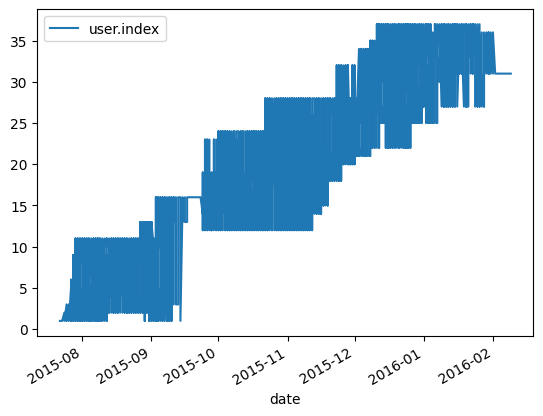

In [14]:
# checking unit overlap for better consistency
df_time_ind = df_hs[["user.index", "date"]]
df_time_ind["date"] = pd.to_datetime(df_time_ind["date"])

df_time_ind.plot("date","user.index")
# range df
#max(df_time_ind[df_time_ind["user.index"] == 1]["date"])


## Define `transform_dnn`

### First pass: assuming all trials start at the same time

In [467]:
def transform_dnn(df, day_partitions = 4, day_measure = 144, units = 37):
    """
    Transfom df into shape suitable for DNN use case.

    Parameters
    ----------
    df : pandas DataFrame
         a matrix of size Z x 10 (with a set of properties to be defined)
         ...
    day_partitions : int
        The number of partitions to split an individual day into. The 
        default value is 4. Maximally, the value of day_partitions is 
        day_measure.
    day_measure : int
        The number of measurements per "day" in df. The default is 144,
        which aligns with the measurements per day in the HeartSteps dataset.
    units : int
        The number of units in df. Default is 37 (in line with the HeartSteps dataset)        
    Returns
    ----------
    tuple (M, A)
    where M is a units x (day_partitions * D) x (day_measure / day_partitions) np array 
    that contains the outcome vectors of interest and A is a np array shape units x (day_partitions * D)
    that indicates in which unit/time combination a treatment was observed.
    D is the maximum length of days observed among all unit trials.
    """
    # first, find the maximum trial length in days
    # units are 1-indexed
    max_days = 0
    num_days = []
    for i in range(1, units + 1):
        len_i = len(df[df['user.index'] == i]) // day_measure
        num_days.append(len_i)
        if len_i > max_days:
            max_days = len_i
    # init M and A
    M = np.zeros((units, day_partitions * max_days, day_measure // day_partitions))
    A = np.zeros((units, day_partitions * max_days))
    
    for i in range(units):
        # note: i is used to index into M and A.
        # unit_ind is used to retrieve unit specific values from df
        unit_ind = i + 1
        
        # slice by unit
        df_unit = df.loc[df["user.index"] == unit_ind]
        
        # pad first to max trial length to maintain partition size across units
        trial_steps = df_unit["steps"].to_numpy()
        trial_trt = df_unit["treatment"].to_numpy()
        if num_days[i] < max_days:
            # pad with 0s, step values are masked by trt
            pad = np.empty((max_days - num_days[i]) * day_measure)
            pad.fill(np.nan)
            trial_steps = np.append(trial_steps, pad)
            pad_trt = np.zeros((max_days - num_days[i]) * day_measure)
            trial_trt = np.append(trial_trt, pad_trt)
            
        # first split into days, then into partitions
        lst_days = np.split(trial_steps, max_days)
        parts = np.array([np.split(x, day_partitions) for x in lst_days])
         
        # Shape of parts is max_days x day_partitions x (day_measure // day_partitions)
        # Flatten along d dimension to achieve (day_partitions * max_days) x (day_measure // day_partitions) shape
        unit_parts = parts.reshape((max_days * day_partitions, day_measure // day_partitions))
        
        # Repeat for treatment col. 
        lst_days_trt = np.split(trial_trt, max_days)
        parts_trt = np.array([np.split(x, day_partitions) for x in lst_days_trt])
        unit_trt = parts_trt.reshape((max_days * day_partitions, day_measure // day_partitions))
        
        # if any of the trt values within the partition is 1, set the value in the final array to 1
        # if the user is unavailable for any period during the partition and does not receive treatment,
        # then the value in the masking array is 2
        mask_1 = np.any(unit_trt == 1, axis = 1)
        # only want to have 2 in the final array where 2 is the only non-observed value
        mask_2 = np.logical_and(np.any(unit_trt == 2, axis = 1), np.logical_not(mask_1))
        
        unit_trt_agg = np.zeros(unit_trt.shape[0])
        # unit_trt_agg = unit_trt.any(axis = 1).astype(int)
        unit_trt_agg[mask_1] = 1
        unit_trt_agg[mask_2] = 2
        
        M[i] = unit_parts
        A[i] = unit_trt_agg
        A = A.astype('int32')
    return M, A
    

## Testing `transform_dnn` with simulated symmetrical data

We create a small test dataset as a proof of concept of the above data transformation. This data set will have 3 units over a time span of 4 days, with 12 measurements a day. We partition each day into 3 segments (4 measurements per partition). The treatment is randomly applied across each day and time span. This is a simpler example than the actual use case, as the number of days within the trial is consistent for all users. See the section below for a more complex example.

In [ ]:
# create test set

# user inds
u1 = np.repeat(1, 12 * 4)
u2 = np.repeat(2, 12 * 4)
u3 = np.repeat(3, 12 * 4)
user_index = np.concatenate((u1, u2, u3))

# step measurements (for simplicity, between 1 and 10)
rng = np.random.default_rng()
u1_steps = rng.integers(low=1, high=10, size=12 * 4)
u2_steps = rng.integers(low=1, high=10, size=12 * 4)
u3_steps = rng.integers(low=0, high=10, size=12 * 4)
steps = np.concatenate((u1_steps, u2_steps, u3_steps))
 
# treatment measurements
# in practice, it seems much more likely to see no treatment rather than a treatment
u1_trt = np.random.choice([0, 1, 2], 12 * 4, p=[0.7, 0.2, 0.1])
u2_trt = np.random.choice([0, 1, 2], 12 * 4, p=[0.7, 0.2, 0.1])
u3_trt = np.random.choice([0, 1, 2], 12 * 4, p=[0.7, 0.2, 0.1])
trt = np.concatenate((u1_trt, u2_trt, u3_trt))

# time of measurements
#single = pd.Series(pd.date_range("2024-06-14", "2024-06-18", inclusive = "left", freq = '2h'))
# create final dataframe
final_np = np.stack((user_index, steps, trt), axis = 1)
df_symtest = pd.DataFrame(final_np, columns = ["user.index", "steps", "treatment"]) 
#df_symtest["date_time"] = pd.concat([single, single, single]).reset_index(drop = "True")
with pd.option_context("display.max_rows", None, "display.max_columns", None):
  display(df_symtest)

Now that we have created our test set, we can use `transform_dnn_pad` to demonstrate the desired transformation properties.

In [41]:
M, A = transform_dnn(df_symtest, day_partitions = 3, day_measure = 12, units = 3)
M

array([[[5., 2., 8., 4.],
        [7., 9., 4., 6.],
        [5., 3., 4., 3.],
        [9., 8., 5., 3.],
        [5., 3., 8., 3.],
        [7., 4., 6., 5.],
        [5., 8., 5., 1.],
        [6., 7., 6., 3.],
        [1., 7., 3., 5.],
        [2., 2., 4., 3.],
        [2., 5., 2., 6.],
        [3., 2., 7., 7.]],

       [[7., 5., 2., 4.],
        [2., 7., 9., 8.],
        [5., 7., 7., 2.],
        [5., 6., 9., 2.],
        [8., 2., 6., 1.],
        [1., 7., 1., 1.],
        [2., 4., 6., 6.],
        [1., 1., 3., 5.],
        [3., 8., 8., 7.],
        [9., 5., 3., 7.],
        [2., 2., 6., 4.],
        [3., 2., 5., 5.]],

       [[4., 5., 9., 4.],
        [0., 7., 7., 4.],
        [3., 2., 3., 0.],
        [6., 3., 1., 2.],
        [8., 4., 6., 3.],
        [4., 9., 7., 9.],
        [6., 6., 7., 6.],
        [3., 7., 7., 3.],
        [1., 1., 4., 6.],
        [8., 1., 9., 9.],
        [2., 9., 2., 4.],
        [8., 3., 3., 4.]]])

In [43]:
A

array([[1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 2, 1],
       [2, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 0],
       [1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 0]])

## Testing `transform_dnn` on simulated asymmetrical data

Next, we test the function on a dataset with asymmetrical trial periods. As before, we will have 3 units, but this time, one of the units has a longer 6 day trial period. The remaining units have a 4 day trial period. There are still 12 measurements a day, and each day has 3 segments.

In [49]:
# create test set
# user inds, u1 has 6 day trial period
u1 = np.repeat(1, 12 * 6)
u2 = np.repeat(2, 12 * 4)
u3 = np.repeat(3, 12 * 4)
user_index = np.concatenate((u1, u2, u3))

# step measurements (for simplicity, between 1 and 10)
rng = np.random.default_rng()
u1_steps = rng.integers(low=1, high=10, size=12 * 6)
u2_steps = rng.integers(low=1, high=10, size=12 * 4)
u3_steps = rng.integers(low=0, high=10, size=12 * 4)
steps = np.concatenate((u1_steps, u2_steps, u3_steps))
 
# treatment measurements
# in practice, it seems much more likely to see no treatment rather than a treatment
u1_trt = np.random.choice([0, 1, 2], 12 * 6, p=[0.7, 0.2, 0.1])
u2_trt = np.random.choice([0, 1, 2], 12 * 4, p=[0.7, 0.2, 0.1])
u3_trt = np.random.choice([0, 1, 2], 12 * 4, p=[0.7, 0.2, 0.1])
trt = np.concatenate((u1_trt, u2_trt, u3_trt))

#single = pd.Series(pd.date_range("2024-06-14", "2024-06-18", inclusive = "left", freq = '2h'))
#longer = pd.Series(pd.date_range("2024-06-14", "2024-06-20", inclusive = "left", freq = '2h'))
# create final dataframe
final_np = np.stack((user_index, steps, trt), axis = 1)
df_asymtest = pd.DataFrame(final_np, columns = ["user.index", "steps", "treatment"])
#df_asymtest["date_time"] = pd.concat([longer, single, single]).reset_index(drop = "True")
df_asymtest

,user.index,steps,treatment
0,1,1,0
1,1,7,0
2,1,5,0
3,1,6,0
4,1,1,0
...,...,...,...
163,3,5,0
164,3,7,0
165,3,7,0
166,3,4,0


In [50]:
M_a, A_a = transform_dnn(df_asymtest, day_partitions = 3, day_measure = 12, units = 3)

In [51]:
M_a

array([[[ 1.,  7.,  5.,  6.],
        [ 1.,  1.,  7.,  2.],
        [ 4.,  6.,  7.,  8.],
        [ 4.,  2.,  9.,  4.],
        [ 3.,  1.,  6.,  7.],
        [ 5.,  2.,  5.,  3.],
        [ 8.,  6.,  8.,  8.],
        [ 5.,  3.,  3.,  9.],
        [ 4.,  8.,  7.,  8.],
        [ 1.,  2.,  5.,  1.],
        [ 5.,  5.,  9.,  6.],
        [ 3.,  5.,  9.,  8.],
        [ 9.,  5.,  7.,  3.],
        [ 6.,  9.,  5.,  9.],
        [ 7.,  4.,  7.,  1.],
        [ 9.,  7.,  3.,  6.],
        [ 1.,  3.,  1.,  2.],
        [ 7.,  9.,  3.,  4.]],

       [[ 7.,  4.,  8.,  5.],
        [ 8.,  7.,  9.,  3.],
        [ 6.,  3.,  3.,  6.],
        [ 8.,  4.,  1.,  2.],
        [ 3.,  8.,  3.,  4.],
        [ 7.,  5.,  9.,  1.],
        [ 1.,  1.,  3.,  4.],
        [ 7.,  8.,  4.,  4.],
        [ 6.,  9.,  8.,  9.],
        [ 9.,  2.,  6.,  8.],
        [ 8.,  3.,  6.,  1.],
        [ 5.,  3.,  4.,  3.],
        [nan, nan, nan, nan],
        [nan, nan, nan, nan],
        [nan, nan, nan, nan],
        

In [52]:
A_a

array([[0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 2, 0, 1, 1, 1, 1, 1, 1],
       [1, 0, 1, 1, 0, 1, 0, 0, 1, 2, 0, 1, 0, 0, 0, 0, 0, 0],
       [1, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0]])

## Test `transform_dnn` on HeartSteps dataset

Finally, we test `transform_dnn` on its primary use case, the HeartSteps dataset. We use the `treatment` indicator as defined above.

We can see that there are 37 units. Time statistics run from 9:05 to 21:00 at 5 minute intervals, yielding 12 observations per hour for 12 hours. This means that there are 144 measurements per day. We will demonstrate by partitioning the data into 4 sections per day (i.e. each section has 36 measurements). We may later adjust this measure to optimize neighborhood size/granularity of outcome.

In [468]:
# note/question: it seems that 4 measurements may be too granular to find enough neighbors
M_hs, A_hs = transform_dnn(df_hs, day_partitions = 144, day_measure = 144, units = 37)

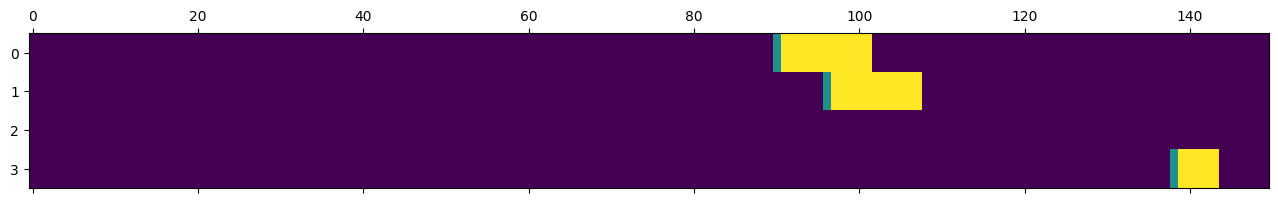

In [475]:
matshow(A_hs[0:4, 0:150], aspect = 'auto')

### NN feasibility of mean-flattened Heartsteps data

First, we want to get a sense of how many observed (treated) values we have, since it seems that the treatment is applied relatively infrequently. If we have too few of these observed values, it could limit the number of potential neighbors that we could use to impute value.

In [70]:
nz_e = len(np.nonzero(A_hs)[0])
print("There are " + str(nz_e) + " nonzero entries")
print("The ratio of nonzero to zero entries is " + str(nz_e / (A_hs.size)))  

There are 1619 nonzero entries
The ratio of nonzero to zero entries is 0.05787930787930788


A $\sim\frac{1}{20}$ of zero to nonzero entries is pretty low. Let's see how it might affect average potential neighborhood size. To do this, we examine each zero entry in the masking matrix and consider how many possible neighbors could be used to impute it. Then we take the average number of possible neighbors.

In [71]:
# this is using item-item or time-time
total_pos_nn = 0
obs = np.nonzero(A_hs == 0)
for i in range(len(obs[0])): 
    total_pos_nn += np.sum(A_hs[obs[0][i], :])
print(total_pos_nn / len(obs[0]))
    

59.83823473608318


## Li 2019 Nearest Neighbors Implementation

We implement the user-user nearest neighbors algorithm as defined in Nearest Neighbors for Matrix Estimation Interpreted as Blind Regression for Latent Variable Model (Li et al. 2019). More specifically, we construct Algorithm 2, which can be found in Section III [here](https://arxiv.org/abs/1705.04867).

First, to align the NN implementation with the data format considered above, we define a function to collapse the partitioned measurements dimension (3rd dim) to its mean. Then, we construct the necessary functions as defined in Li 2019.

In [219]:
# should optimize by precomputing row dissimilarities
def mean_collapse(A, d = 2):
    """
    Returns A (3d array) with dth dimension collapsed as mean
    """
    return np.nanmean(A, axis = d)

def dissim_col(O, M, u, v):
    """
    Returns the col dissimilarity between cols u and v
    in O
    
    Parameters
    ----------
    O : a matrix of size a x b
    M : a masking matrix of size a x b that
        dictates which entries of O are known 
    u : the index of a cols in O
    v : the index of a col in O

    Returns
    ----------
    d_col : the col dissimilarity between u and v (float)
    """
    obv_col_mask = np.logical_and(M[:, u] == 1, M[:, v] == 1)
    overlap = np.nansum(obv_col_mask)
    if not overlap:
        return float('inf')    
    sd = (O[:, u] - O[:, v])**2 * obv_col_mask 
    msd = (1 / overlap) * np.nansum(sd)
    return msd
    
    
def dissim_row(O, M, u, v):
    """
    Returns the row dissimilarity between rows u and v
    in O
    
    Parameters
    ----------
    O : a matrix of size a x b
    M : a masking matrix of size a x b that
        dictates which entries of O are known 
    u : the index of a row in O
    v : the index of a row in O

    Returns
    ----------
    d_row : the row dissimilarity between u and v (float)
    """
    obv_col_mask = np.logical_and(M[u] == 1, M[v] == 1)
    overlap = np.nansum(obv_col_mask)
    if not overlap:
        return float('inf')    
    sd = (O[u] - O[v])**2 * obv_col_mask 
    msd = (1 / overlap) * np.nansum(sd)
    return msd

def all_dissims(O, M, ax):
    """
    Returns all dissimilarities in matrix O masked by M

    Parameters
    ----------
    O : a matrix of size a x b
    M : a masking matrix of size a x b that
        dictates which entries of O are known
    ax : specifies which dimension of O to compute similarities over
        (either 0 -> rows, or 1 -> cols)
    """
    # apply mask to the original matrix -> if something is not observed, then
    # should not include in the mean calcs
    O[M != 1] = np.nan 
    if ax == 1:
        O = O.T
        M = M.T
    O_br = O[:, None] # add extra dim for broadcast operation
    # all row dissims between pairs of rows
    dis = (O_br - O)**2
    # take mean over the sample dimension (now the 2nd dim)
    mean_row_dis = np.nanmean(dis, axis = 2)
    # overlap between every
    overlap = np.sum(M[:, None] * M, axis = 2)
    zs = np.nonzero(overlap == 0)
    overlap[zs] = np.nan
    
    # rows with 0 overlap will have nan in this matrix
    # entry cannot be own neighbor, so dist is infinite
    mean_ovr = mean_row_dis / overlap
    np.fill_diagonal(mean_ovr, np.inf)
    return mean_ovr

def row_dissims(O, M, i, ax):
    """
    Compute the dissimilarities wrt to row i of O INCOMPLETE
    """
    if ax == 0:
        dis = (O[i] - O)**2
        mean_dis = np.nanmean(dis, axis = 1)
        overlap = np.nansum(M[i] * M, axis = 1)
        mean_ovr = mean_dis / overlap
        # the dissimilarity between a row and itself is nan
        mean_ovr[i] = np.nan
    else:
        # get columns of things to estimate
        col_inds = np.nonzero(M[i] == 0)
        cols = O[:, col_inds] - O
    return mean_ovr


def nn_fast(dissims, u, eta):
    """
    Returns eta-radius neighborhood around row/col index u.
    """
    return np.nonzero(dissims[u] < eta)


def estimate_rowcol_fast(Z, dissims, u, eta, variation):
    """
    Estimate values for row/col u in Z

    Variation denotes whether u is a row index or a col index
    """
    nn_inds = dissims[u] <= eta
    if variation == "row":
        # then nn_inds are row inds
        return np.nanmean(Z[nn_inds, :], axis = 0)
    else: 
        return np.nanmean(Z[:,nn_inds], axis = 1)

def estimate_cell_fast(Z, M, dissims, i, j, eta, variation):
    """
    Estimate value for a single cell
    """
    if variation == "row":
        nn_ij = np.nonzero(dissims[i] <= eta)
        # can change this later
        if len(nn_ij) == 0:
            return np.nan
        return np.nanmean(Z[nn_ij, j][M[nn_ij, j] == 1])
    else variation == "col":
        nn_ij = np.nonzero(dissims[j] <= eta)
        if len(nn_ij) == 0:
            return np.nan
        return np.nanmean(Z[i, nn_ij][M[i, nn_ij] == 1])
    

def nearest_neighbors(O_1, u, M, eta, variation = "user-user"):
    """
    Returns the B neighborbood around u using rows/cols in O_1 within
    radius eta. 
    
    Parameters
    ----------
    O_1 : a matrix of size c x d
    u : index of row/col u in O_1 and M
    M : a masking matrix of size c x d that
        dictates which entries of O_1 are known 
    eta : radius of B neighborhood
    variation : "user-user", "item-item" dictates which variation
                of nearest neighbors is being used. Default: "user-user"
    
    Returns
    ----------
    B : neighborhood (indicies of most similar rows/cols)
        with radius eta
    """
    if variation == "item-item":
        dissims = np.array([dissim_col(O_1, M, u, v) for v in range(len(O_1[0]))])
    else:
        dissims = np.array([dissim_row(O_1, M, u, v) for v in range(len(O_1))])        
    # remove u from neighbors
    #dissims = np.delete(dissims, u, 1)
    B = np.nonzero(dissims <= eta)
    return B
    
    
    
def estimate_li_nn(Z, M, eta):
    """
    Returns A_hat, the estimate of partially unobvserved
    matrix A using Nearest Neighbors imputation
    
    Parameters
    ----------
    Z : an array of size m x n x q
    M : a masking matrix of size m x n that
        dictates which entries of Z are known 
    eta : radius of B neighborhood
    
    Returns
    ----------
    A_hat : the estimate of partially unobvserved matrix A
    """
    Z = mean_collapse(Z, d = 2)
    m, n = Z.shape
    A_hat = np.zeros((m, n))
    for u in range(m):
        for v in range(n):
            # sample splitting: artificially mask out values in the column of the
            # cell we are interested in
            O_1 = Z.copy()
            O_2 = Z[:, j]
            M_v = M.copy()
            M_v[:,j] = 0
            u_neighbors = nearest_neighbors(O_1, u, M_v, eta)
            # only select observed neighbors
            mask = M[u_neighbors, v]
            pos_nn = Z[u_neighbors, v]
            masked_nn = pos_nn[mask == 1]
            if not len(masked_nn):
                A_hat[u, v] = 0
            else:
                A_hat[u, v] = np.nanmean(masked_nn)
    return A_hat

def estimate_li_nn_inds(Z, M, eta, v_inds):
    """
    Returns A_hat, the estimate of partially unobvserved
    matrix A using Nearest Neighbors imputation, with only indices specified
    by v_inds estimated (user-user variation)
    
    Parameters
    ----------
    Z : an array of size m x n x q
    M : a masking matrix of size m x n that
        dictates which entries of Z are known 
    eta : radius of B neighborhood
    v_inds : indices to estimate, tuple of (x_coords, y_coords)
    
    Returns
    ----------
    A_hat : the estimate of values in partially unobserved matrix A specified by v_inds
    """
    row_coords, col_coords = v_inds
    Z = mean_collapse(Z, d = 2)
    m, n = Z.shape
    A_hat = np.zeros((m, n))
    for i in range(len(row_coords)):
        u = row_coords[i]
        j = col_coords[i]
        # sample splitting: artificially mask out values in the column of the
        # cell we are interested in
        O_1 = Z.copy()
        O_2 = Z[:, j]
        M_j = M.copy()
        # invert M to find neighbors among a = 0 (denser)
        #M_j = np.logical_not(M)
        # still keep col j out of consideration
        M_j[:,j] = 0
        u_neighbors = nearest_neighbors(O_1, u, M_j, eta)
        mask = M[u_neighbors, j]
        pos_nn = Z[u_neighbors, j]
        masked_nn = pos_nn[mask == 1]
        if not len(masked_nn):
            A_hat[u, j] = 0
        else:
            A_hat[u, j] = np.nanmean(masked_nn)
    return A_hat
        
def estimate_li_nn_inds_cols(Z, M, eta, v_inds):
    """
    Returns A_hat, the estimate of partially unobvserved
    matrix A using Nearest Neighbors imputation, with only indices specified
    by v_inds estimated (item-item variation)
    
    Parameters
    ----------
    Z : an array of size m x n x q
    M : a masking matrix of size m x n that
        dictates which entries of Z are known 
    eta : radius of B neighborhood
    v_inds : indices to estimate, tuple of (x_coords, y_coords)
    
    Returns
    ----------
    A_hat : the estimate of values in partially unobserved matrix A specified by v_inds
    """
    row_coords, col_coords = v_inds
    Z = mean_collapse(Z, d = 2)
    m, n = Z.shape
    A_hat = np.zeros((m, n))
    for i in range(len(row_coords)):
        u = row_coords[i]
        j = col_coords[i]
#         O_1  = np.delete(Z, u, axis = 0)
#         O_2 = Z[u, :]
#         M_j = np.delete(M, u, axis = 0)
        # sample splitting: artificially mask out values in the row of the
        # cell we are interested in
        O_1 = Z.copy()
        O_2 = Z[u, :]
        M_u = M.copy()
        # invert M to find neighbors among M = 0
        #M_u = np.logical_not(M)
        # still keep u row out of consideration
        M_u[u, :] = 0

        j_neighbors = nearest_neighbors(O_1, j, M_u, eta, variation = "item-item")
        mask = M[u, j_neighbors]
        pos_nn = Z[u, j_neighbors]
        masked_nn = pos_nn[mask == 1]
        if not len(masked_nn):
            A_hat[u, j] = 0
        else:
            A_hat[u, j] = np.nanmean(masked_nn)
    return A_hat

# using the indexing strategy i am currently using, A_hat and A are both 1 dimensional. This might change.
def mse(A_hat, A):
    """
    Returns the mean squared error of estimate A_hat from ground truth A
    """
    return np.nanmean((A_hat - A)**2)

In [ ]:
# load in the data sets
A_hs = np.load("heartsteps_mask.npy")
M_hs = np.load("heartsteps_data.npy")
M_hs = M_hs[:, :, :, None]

### Checking Li 2019 implementation correctness with worked example

In order to look for bugs in our cross validation and Li 2019 implementations, we create a sample dataset with some nice properties and compute the similarities by hand. This doesn't guarantee correctness, but it will catch simple errors/mistakes in understanding.

To start, we create a simulated datasest with 6 users over a two day trial period. There are 6 measurements per day and each day is broken into 3 segments. 3 of the users (A, B, and C) are similar to each other (roughly more steps in the evening/last measurement periods in the day) and the other 3 users (D, E, F) are different from the first 3 and similar to each other (roughly more steps in the morning/early measurement periods.  

Let's suppose the matrix is fully observed. To simulate a validation set, we mask out one segement for each user - these are the values we will try to impute.

In [200]:
# user inds
uA = np.repeat(1, 6 * 2)
uB = np.repeat(2, 6 * 2)
uC = np.repeat(3, 6 * 2)

uD = np.repeat(4, 6 * 2)
uE = np.repeat(5, 6 * 2)
uF = np.repeat(6, 6 * 2)

user_index = np.concatenate((uA, uB, uC, uD, uE, uF))

# step measurements
steps_uA = [1, 1, 2, 3, 5, 9, 1, 1, 3, 4, 5, 10]
steps_uB = [0, 2, 2, 4, 5, 11, 0, 2, 3, 3, 4, 12]
steps_uC = [0, 0, 2, 5, 7, 10, 2, 2, 1, 5, 6, 9]

steps_uD = [10, 5, 4, 3, 1, 1, 9, 5, 3, 2, 1, 1]
steps_uE = [12, 4, 3, 3, 2, 0, 11, 5, 4, 2, 2, 0]
steps_uF = [9, 6, 5, 1, 2, 2, 10, 7, 5, 2, 0, 0]
steps = np.concatenate((steps_uA, steps_uB, steps_uC, steps_uD, steps_uE, steps_uF))

# treatment indicators
trt_uA = [1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0]
trt_uB = [0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0]
trt_uC = [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0]

trt_uD = [1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0]
trt_uE = [0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0]
trt_uF = [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0]

#single = pd.Series(pd.date_range("2024-06-14", "2024-06-16", inclusive = "left", freq = '4h'))

trt = np.concatenate((trt_uA, trt_uB, trt_uC, trt_uD, trt_uE, trt_uF))
final_np = np.stack((user_index, steps, trt), axis = 1)
df_nn_test = pd.DataFrame(final_np, columns = ["user.index", "steps", "treatment"])
#df_nn_test["date_time"] = pd.concat([single, single, single, single, single, single]).reset_index(drop = "True")
df_nn_test


,user.index,steps,treatment
0,1,1,1
1,1,1,0
2,1,2,1
3,1,3,0
4,1,5,0
...,...,...,...
67,6,7,1
68,6,5,1
69,6,2,1
70,6,0,0


In [201]:
data_full, mask = transform_dnn(df_nn_test, day_partitions = 3, day_measure = 6, units = 6)

In [202]:
data_full

array([[[ 1.,  1.],
        [ 2.,  3.],
        [ 5.,  9.],
        [ 1.,  1.],
        [ 3.,  4.],
        [ 5., 10.]],

       [[ 0.,  2.],
        [ 2.,  4.],
        [ 5., 11.],
        [ 0.,  2.],
        [ 3.,  3.],
        [ 4., 12.]],

       [[ 0.,  0.],
        [ 2.,  5.],
        [ 7., 10.],
        [ 2.,  2.],
        [ 1.,  5.],
        [ 6.,  9.]],

       [[10.,  5.],
        [ 4.,  3.],
        [ 1.,  1.],
        [ 9.,  5.],
        [ 3.,  2.],
        [ 1.,  1.]],

       [[12.,  4.],
        [ 3.,  3.],
        [ 2.,  0.],
        [11.,  5.],
        [ 4.,  2.],
        [ 2.,  0.]],

       [[ 9.,  6.],
        [ 5.,  1.],
        [ 2.,  2.],
        [10.,  7.],
        [ 5.,  2.],
        [ 0.,  0.]]])

In [191]:
mask

array([[1, 1, 0, 1, 1, 1],
       [0, 1, 1, 1, 1, 1],
       [1, 1, 1, 1, 1, 0],
       [1, 1, 0, 1, 1, 1],
       [0, 1, 1, 1, 1, 1],
       [1, 1, 1, 1, 1, 0]])

First, we take the mean of the partitioned dimension to achieve the 2D structure.

In [192]:
data = mean_collapse(data_full)
data

array([[1. , 2.5, 7. , 1. , 3.5, 7.5],
       [1. , 3. , 8. , 1. , 3. , 8. ],
       [0. , 3.5, 8.5, 2. , 3. , 7.5],
       [7.5, 3.5, 1. , 7. , 2.5, 1. ],
       [8. , 3. , 1. , 8. , 3. , 1. ],
       [7.5, 3. , 2. , 8.5, 3.5, 0. ]])

Next, let's calculate the dissimilarities between each row. This is the mean squared difference between overlapping observed values. 

Dissim A-B: $\frac{((3 - 2.5)^2 + (1 - 1)^2 + (3.5 - 3.0)^2 + (7.5 - 8)^2)}{4} = \frac{0.75}{4} = 0.1874$

Dissim A-C: $\frac{(1-0)^2 + (3.5 - 2.5)^2 + (1)^2 + (0.5)^2 + 0^2}{4} = \frac{3.25}{4} = 0.8125$

Dissim A-D: $\frac{6.5^2 + 1^2 + 6^2 + 1^2 + 6.5^2}{5} = \frac{122.5}{5} = 24.5$

Dissim A-E: $\frac{0.5^2 + 6^2 + 7^2 + 6.5^2}{4} = 31.875$

Dissim A-F: $\frac{6.5^ + 0.5^2 + 7.5^2 + 0}{4} = 24.6875$ 

Dissim B-C: $\frac{0.5^2 + 0.5^2 + 1^2 + 0^2}{4} = 0.375$

Dissim B-D: $\frac{0.5^2 + 6^2 + 0.5^2 + 7^2}{4} = 21.375$

Dissim B-E: $\frac{0^2 + 7^2 + 7^2 + 0^2 + 7^2}{5} = 29.4$

Dissim B-F: $\frac{0^2 + 6^2 + 7.5^2 + 0.5^2}{4} = 23.125$

Dissim C-D: $\frac{7.5^2 + 0^2 + 5^2 + 0.5^2}{4} = 20.375$

Dissim C-E: $\frac{0.5^2 + 7^2 + 7^2 + 0^2}{4} = 24.5625$

Dissim C-F: $\frac{7.5^2 + 0.5^2 + 6.5^2 + 6.5^2 + 0.5^2}{5} = 28.25$

Dissim D-E: $\frac{0.5^2 + 1^2 + 0.5^2 + 0^2}{4} = 0.375$

Dissim D-F: $\frac{0^2 + 0.5^2 + 0.5^2 + 1^2}{4} = 0.375$

Dissim E-F: $\frac{0^2 + 1^2 + 0.5^2 + 0.5^2}{4} = 0.375$

We can see that A-B-C and D-E-F are two distinct neighborhoods with $\eta = 1$. Given this, we impute the missing values by taking the average of the neighbors at the column where an observation is missing. 

In [203]:
inv_mask = ~(mask.astype(bool))
mask


array([[1, 1, 0, 1, 1, 1],
       [0, 1, 1, 1, 1, 1],
       [1, 1, 1, 1, 1, 0],
       [1, 1, 0, 1, 1, 1],
       [0, 1, 1, 1, 1, 1],
       [1, 1, 1, 1, 1, 0]])

In [204]:
data

array([[1. , 2.5, 7. , 1. , 3.5, 7.5],
       [1. , 3. , 8. , 1. , 3. , 8. ],
       [0. , 3.5, 8.5, 2. , 3. , 7.5],
       [7.5, 3.5, 1. , 7. , 2.5, 1. ],
       [8. , 3. , 1. , 8. , 3. , 1. ],
       [7.5, 3. , 2. , 8.5, 3.5, 0. ]])

In [205]:
data_imputed = data.copy()
data_imputed[0, 2] = 8.25
data_imputed[1, 0] = 0.5
data_imputed[2, 5] = 7.75
data_imputed[3, 2] = 1.5
data_imputed[4, 0] = 7.5
data_imputed[5, 5] = 1

In [213]:
# these are the imputed predictions
pred = data_imputed[inv_mask]
pred

array([8.25, 0.5 , 7.75, 1.5 , 7.5 , 1.  ])

In [214]:
# this is the ground truth
truth = data[inv_mask]
truth

array([7. , 1. , 7.5, 1. , 8. , 0. ])

In [215]:
# the mse is:
mse(pred, truth)

0.5625

When we compute the MSE of the prediction by hand following Li 2019's method, we get 0.5625. Now we compute it using our implementation.

In [220]:
inds = np.nonzero(inv_mask)
#A_hat = estimate_rowcol_fast()
A_hat = estimate_li_nn_inds(data_full, mask, eta = 1, v_inds = inds)
pred = A_hat[inds]
mse(pred, truth)

0.5625

Now, we compute the same predictions for the item-item strategy.

In [221]:
inds = np.nonzero(inv_mask)

A_hat = estimate_li_nn_inds_cols(data_full, mask, eta = 3, v_inds = inds)
pred = A_hat[inds]
mse(pred, truth)

0.875

## Cross Validation for $\eta$

Next, we implement cross-validation for the $\eta$ radius parameter. Given a dataset, an error metric, and an estimation function, we evaluate a range of values of $\eta$. 

In [105]:
# notes
    # we are only interested in the estimates that `estimate` makes for the
    # validation set in particular. For any validation fold, we must only consider observed values (need a ground truth)
    # We mask over these values to estimate, then extract the estimates using the original mask to compute the error.
    
# pick one cell to impute for the heartsteps to check correctness for Li 2019

In [121]:
def cross_validate_nn(Z, M, k, eta, estimate, error_metric):
    """
    Performs k-fold cross validation on using dataset `Z`, mask `M`, parameters `k` and `eta`,
    estimation function `estimate`, and error `error_metric`
    """
    # find observed indices and create splits off of those
    obvs_inds_x, obvs_inds_y = np.nonzero(M == 1)
    
    # shuffle the x and y coordinates in the same way to maintain valid coords
    shuf_inds = np.arange(len(obvs_inds_x))
    np.random.shuffle(shuf_inds)
    shuf_obvs_inds = np.array((obvs_inds_x[shuf_inds], obvs_inds_y[shuf_inds]))
    # split coordinates into k-folds
    folds = np.array_split(shuf_obvs_inds, k, axis = 1)
    tot_error = 0
    fin_k = k
    for i in range(k):
        # indices of the observed outcomes in the validation set in this iteration
        folds_ind = tuple(folds[i])
        # ground truth
        val_data = mean_collapse(Z[folds_ind], d = 1)
        est_mask = M.copy()
        # hide observed values in the validation set
        est_mask[folds_ind] = 0
        A_hat = estimate(Z, est_mask, eta, folds_ind)
        # extract validation points
        est_val = A_hat[folds_ind]
        err = error_metric(est_val, val_data)
        if np.isnan(err):
            err = 0
            fin_k -= 1
        tot_error += err
    # return average error over k folds
    return tot_error / fin_k
 

### Cross validation for Li (2019) NN

We use k-fold cross validation to tune hyperparameter $\eta$ for the Li (2019) NN model implemented above. We show results using k = 5 and k = # observed outcomes (LOOCV). 

In [153]:
# first, compute dissims from a subsection of the data to get a sense of the range of distances
# notation: should change later, but M_hs is Z and A_hs is M

rnd_ind = np.random.choice(37, size = 10, replace = False)
all_combs = product(rnd_ind, rnd_ind)
M_hs_collapse = mean_collapse(M_hs)
for u, v in all_combs:
    print(dissim_row(M_hs_collapse, A_hs, u, v))

len(A_hs[A_hs == 1])

0.0
2192.581349206349
1677.8179494598764
3286.0545267489706
2301.4559082892415
1425.438143004115
5050.6320546737215
226.33281893004113
4224.826646090536
3813.073005698006
2192.581349206349
0.0
1526.8618827160494
2926.867945326278
3079.1076388888887
8106.286779835391
5257.695326278659
129.33063271604937
4338.933641975307
1927.3020404663919
1677.8179494598764
1526.8618827160494
0.0
1308.8871913580244
382.9513888888889
269.0297067901234
788.4931742640077
1143.4243827160494
857.9251543209876
977.5050925925926
3286.0545267489706
2926.867945326278
1308.8871913580244
0.0
1215.2924382716049
5380.932355967078
4750.074514991181
1178.367283950617
736.4311728395062
4142.545945566779
2301.4559082892415
3079.1076388888887
382.9513888888889
1215.2924382716049
0.0
1720.8805555555555
1873.2754629629628
301.40817901234567
845.3027777777778
798.9182741769547
1425.438143004115
8106.286779835391
269.0297067901234
5380.932355967078
1720.8805555555555
0.0
772.8248456790124
5356.809220679013
3134.164660493827

C:\Users\Caleb\AppData\Local\Temp\ipykernel_19552\521688444.py:5: RuntimeWarning: Mean of empty slice
  return np.nanmean(A, axis = d)


1001

In [156]:
# try using HeartSteps data with eta 10 to 500? are there other hyperparameter optimizations to use? 
# k = 5
eta_range = np.arange(10, 5000, step = 100)
#eta_range = [350.]

min_error = float("inf")
best_eta = 0
for eta in eta_range:
    error = cross_validate_nn(M_hs, A_hs, 5, eta, estimate_li_nn_inds_cols, mse)
    print("Error for eta " + str(eta) + ": " + str(error))
    if error < min_error:
        min_error = error
        best_eta = eta


C:\Users\Caleb\AppData\Local\Temp\ipykernel_19552\4151332911.py:5: RuntimeWarning: Mean of empty slice
  return np.nanmean(A, axis = d)


0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
1
0
0
0
0
1
0
0
0
0
0
0
0
1
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
1
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
1
1
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
1
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
1
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
1
0
0
1
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
1
0
0
1
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0


In [157]:
print(best_eta)
print(min_error)

4610
2034.1204773823235


In [122]:
# k = # observed entries
k = len(np.nonzero(A_hs)[0])
min_error = float("inf")
best_eta = 0
for eta in eta_range:
    error = cross_validate_nn(M_hs, A_hs, 1009, eta, estimate_li_nn_inds_cols, mse)
    print("Error for eta " + str(eta) + ": " + str(error))
    if error < min_error:
        min_error = error
        best_eta = eta

C:\Users\Caleb\AppData\Local\Temp\ipykernel_19552\1443676286.py:5: RuntimeWarning: Mean of empty slice
  return np.nanmean(A, axis = d)
C:\Users\Caleb\AppData\Local\Temp\ipykernel_19552\1443676286.py:218: RuntimeWarning: Mean of empty slice
  return np.nanmean((A_hat - A)**2)


Error for eta 10: 3946.709949992139
Error for eta 110: 2893.686866924073
Error for eta 210: 2693.9205349276835
Error for eta 310: 2450.771408892189
Error for eta 410: 2326.946851284477
Error for eta 510: 2282.836751421857
Error for eta 610: 2309.5623191489867
Error for eta 710: 2285.570638448613
Error for eta 810: 2296.792318638167
Error for eta 910: 2240.1689549275393
Error for eta 1010: 2256.393977551121
Error for eta 1110: 2244.164118785124
Error for eta 1210: 2247.171207884887
Error for eta 1310: 2239.691298939916
Error for eta 1410: 2246.389812376209
Error for eta 1510: 2256.649547376505
Error for eta 1610: 2269.3899417094417
Error for eta 1710: 2256.5184676257995
Error for eta 1810: 2176.0946318455203
Error for eta 1910: 2157.376963621682
Error for eta 2010: 2166.0171312015377
Error for eta 2110: 2153.2273542282496
Error for eta 2210: 2137.4454684820626
Error for eta 2310: 2131.8906934198144
Error for eta 2410: 2124.563919058376
Error for eta 2510: 2117.1980141871354
Error for et

In [123]:
best_eta

2810

### Single unit estimation

In this section, we compute errors on a unit level.

In [222]:
def eval_row(M, A, i, eta, estimator, error):
  """
  Evaluates the `error` metric of unit i in M using `estimator`
  which is an NN model with neighborhood radius `eta`
  """
  # find indices for row i that are observed
  row_obvs_inds = np.nonzero(A[i] == 1)[0]
  inds = (np.repeat(i, len(row_obvs_inds)), row_obvs_inds)
  #print(inds)
  A_c = A.copy()
  A_c[inds] = 0
  estimate = estimator(M, A_c, eta, inds)
  est_inds = estimate[inds]
  truth = mean_collapse(M[inds], d = 1)
  #print(truth)
  return error(est_inds, truth)

def eval_row_fast(M, A, dissims, i, eta, estimator, error, variation):
  """
  Evaluate row faster
  """
  estimate = estimator(M, dissims, i, eta, variation = variation)
  estimate = estimate[A[i] == 1]
  



def print_error_rows(M, A, eta, error):
  """
   Print the error of each row in M
  """
  for i in range(len(M)):
    A_cp = A.copy()
    A_cp[i] = 0 # mask out the row
    # compute item-item dissimilarities
    diss = all_dissims(M, A_cp, 1)
    to_est = np.nonzero(A[i])
    row_error = 0
    for j in range(len(to_est[0])):
      estimate = estimate_cell_fast(M, A, diss, i, j, eta, "col")
      truth = M[i, j]
      row_err += error(estimate, truth)
    avg_row_error = row_error / len(to_est[0])
    print(avg_row_error)

    
    #u_err = eval_row(M, A, i, j, eta, estimator, error)
    #print("Unit " + str(i) + " error: " + str(u_err))


In [223]:
print_error_rows(M_hs, A_hs, 4000, mse)

C:\Users\Caleb\AppData\Local\Temp\ipykernel_19552\3921721799.py:81: RuntimeWarning: Mean of empty slice
  mean_row_dis = np.nanmean(dis, axis = 2)


ValueError: operands could not be broadcast together with shapes (1,1,37) (9072,9072) 

In [161]:
import math
def rmse (A_hat, A):
  return math.sqrt(mse(A_hat, A))

print_error_rows(M_hs, A_hs, 4610, estimate_li_nn_inds_cols, rmse)

C:\Users\Caleb\AppData\Local\Temp\ipykernel_19552\521688444.py:5: RuntimeWarning: Mean of empty slice
  return np.nanmean(A, axis = d)


Unit 0 error: 93.23037588798775
Unit 1 error: 60.82790235662102
Unit 2 error: 57.24542310032367
Unit 3 error: 105.90520390943834
Unit 4 error: 36.7382570533966
Unit 5 error: 72.19633933059553
Unit 6 error: 58.54912921761806
Unit 7 error: 71.78957295075043
Unit 8 error: 47.67808178367505
Unit 9 error: 70.35544805090073
Unit 10 error: 46.47400165805309
Unit 11 error: 62.37889398353464
Unit 12 error: 50.36094768211108
Unit 13 error: 47.040835647589766
Unit 14 error: 39.915446732002785
Unit 15 error: 59.06018111542025
Unit 16 error: 140.9496737529997
Unit 17 error: 36.13084599260494
Unit 18 error: 56.31025622062748
Unit 19 error: 23.211712726159522
Unit 20 error: 59.34854372059057
Unit 21 error: 23.734030000947644
Unit 22 error: 42.57256626343515
Unit 23 error: 55.352348351569596
Unit 24 error: 58.83471450088999
Unit 25 error: 48.12955857072201
Unit 26 error: 40.61656297078021
Unit 27 error: 111.19216308606553
Unit 28 error: 63.4217128230341
Unit 29 error: 171.86877802826655
Unit 30 error:

## Kernel NN/MMD Implementation

We take the same data format as implemented in `transform_dnn` above. Unlike Li (2019), we do not wish to aggregate the measurements in each unit x time cell as a mean. Instead, we will use them to approximate the distribution from which they were drawn. Since we do not have the true distributions of any of the entries, we can validate our performance.


In [170]:
# might need more clarification on how MMD works with empirical distributions, i.e. how to find
# order statistics or values to impute etc..
# translated example
import numpy as np
# Kyuseong's implementation translated from R
def hatMMD_square(dat1, dat2):
    # Takes two data set and returns U-statistics estimator for MMD squared distance 
    val = 0
    N = dat1.shape[0]
    def square_kernel(x, y):
        return (np.nansum(x*y) + 1)**2
    def rbf_kernel(x, y):
    # what to put here - in other implementaion of rbf, had bandwidth ranges
        sigma2 = 5
        return np.exp(-0.5*np.linalg.norm(x - y, axis = 1)**2 / (2 * sigma2))

    for i in range(N - 1):
        for j in range(i + 1, N):
            val += rbf_kernel(dat1[i, :], dat1[j, :]) + rbf_kernel(dat2[i, :], dat2[j, :]) - 2*rbf_kernel(dat1[i, :], dat2[j, :])
    return 2*val/(N*(N - 1))

In [179]:
# need to fix issue with mask, overlap counting due to the new treatment in all of Li, MMD, Wasserstein
full_mask = np.logical_and((A[0] == 1), (A[1] == 1))
print(full_mask)
overlap = np.sum(full_mask == 1)
ol_inds = np.nonzero(full_mask)
print(ol_inds)
print(M_a[0, ol_inds, None].shape[0])
hatMMD_square(M_a[0, ol_inds, None], M_a[1, ol_inds, None])

[False False  True False False False False False False False False False]
(array([2], dtype=int64),)
1


ZeroDivisionError: division by zero

In [1]:
def rbf_kernel(x, y):
    """
    RBF kernel
    x : a x c x d
    ys : j x c x d

    Returns:
    rbf : a j x c array of where rbf_zde = the rbf kernel computation between
    the column z and the column d for cell e.
    """
    # what to put here - in other implementaion of rbf, had bandwidth ranges
    sigma2 = 5
    return np.exp(-0.5*np.linalg.norm(x - y, axis = 3)**2 / (2 * sigma2))

def square_kernel(x, ys):
    """
    Square kernel

    x : c x a x d
    ys : c x j x d

    Returns:
    sq : a x j x c array of where sq_zde = the square kernel computation between
    the column z and the column d for cell e.
    """
    return (np.einsum('cad,cjd->ajc', x, ys) + 1)**2
    
def mmd_sqd(X_i, X_j, kern):
    """
    Return the MMD^2 distance between rows with n measurements in each cell
    X_i and X_j. Each measurement is d dimensional
    
    Parameters:
    ----------
    X_i : c x n x d array
    X_j : a c x n x d array
    kern : kernel function
    
    Returns:
    ----------
    The MMD^2 between corresponding entries in X_i and X_j.
    The output is c dimensional.
    """
    sum_h = 0
    # c are the entries in each row, n is number of measurements
    # in each entry, d is the dimension of each measurement
    c, n, d = X_i.shape
    for l, l_p in itertools.combinations(range(n), r=2):
        if l != l_p:
            x = X_i[:, l] # this is c x d dimensional
            x_p = X_i[:, l_p]
            y = X_j[:, l]
            y_p = X_j[:, l_p]
            sum_h += kern(x, x_p) + kern(y, y_p) - kern(x, y_p) - kern(x_p, y)
    
    return (1 / (n * (n - 1)) * (sum_h))

def mmd_sqd_fast_cols(X_i, X_js, kern):
    """
    Return the MMD^2 distances between a collection of row/cols X_i and a collection of 
    rows/cols X_js. Each row/col has c cells, with n measurements in each cell,
    and d dimensional measurements. X_js is made up of j such rows/cols.

    Note: kern must be defined to handle varying sized inputs (broadcastable)
    
    Parameters:
    ----------
    X_i : c x a x n x d array
    X_js : c x j x n x d array
    kern : kernel function
    
    Returns:
    ----------
    The MMD^2 between corresponding entries in X_i and X_js. 
    Each entry i along the 0th dimension represents the MMD^2 differences across
    cells between column i and all columns j.
    The output is a x j x c dimensional.
    """
    sum_h = 0
    # c are the entries in each col, n is number of measurements
    # in each entry, d is the dimension of each measurement
    c, a, n, d = X_i.shape
    j = X_js.shape[1]

    for l, l_p in itertools.combinations(range(n), r=2):
        if l != l_p:
            x = X_i[:, :, l] # this is c x a x d
            x_p = X_i[:, :,  l_p]
            y = X_js[:, :, l] # this is c x j x d 
            y_p = X_js[:, :, l_p]
            sum_h += kern(x, x_p) + kern(y, y_p) - kern(x, y_p) - kern(x_p, y)
    
    return (1 / (n * (n - 1)) * (sum_h)) # this should be a x j x c
        
    
def dissim_mmd(X, A, i, j, kern):
    """
    Measures the dissimilarity between rows i and j using maximum mean discrepancies (MMD)
    
    Parameters: 
    ----------
    X : N x T x n x d array
    A : N x T matrix that denotes which entries of X are observed
    i : indice of a row in X
    j : indice of row in X
    kern : kernel function
    """
    full_mask = np.logical_and(A[i] == 1, A[j] == 1)
    overlap = np.sum(full_mask)
    if not overlap or i == j:
        # maybe change to np.inf
        return float("inf") 
    col_inds = np.nonzero(full_mask)
    # this removes entries that are not observed across both rows
    i_entries = X[i, col_inds]
    j_entries = X[j, col_inds]
    mmd_dissims = mmd_sqd(i_entries, j_entries, kern) 
    return np.nansum(mmd_dissims) / overlap

def dissim_mmd_col(X, A, i, j, kern):
    """
    Measures the dissimilarity between cols i and j using maximum mean discrepancies (MMD)
    
    Parameters: 
    ----------
    X : N x T x n x d array
    A : N x T matrix that denotes which entries of X are observed
    i : indice of a col in X
    j : indice of col in X
    kern : kernel function
    """
    full_mask = np.logical_and(A[:, i] == 1, A[:, j] == 1)
    overlap = np.sum(full_mask)
    if not overlap or i == j:
        # maybe change to np.inf
        return float("inf") 
    row_inds = np.nonzero(full_mask)
    # this removes entries that are not observed across both rows
    i_entries = X[row_inds, i]
    j_entries = X[row_inds, j]
    mmd_dissims = mmd_sqd(i_entries, j_entries, kern) 
    return np.nansum(mmd_dissims) / overlap

def col_mmd_dissims_fast(X, M, cols, kern):
    """
    Compute the column dissimilarities between columns in the list cols with
    all columns in X masked by M. 

    Parameters:
    ----------
    X : a N x T x n x d array
    M : a N x T matrix that denotes which entries of X are observed
    cols : a list of indices of columns of X
    """
    # mask out values that are not observed with nan
    X_cp = X.copy()
    X_cp[M == 0] = np.nan
    # select columns
    X_cols = X_cp[:, cols]
    # compute mmd scores between the selected columns and all matrix columns
    # X_cp is N x T x n x d = c x j x n x d
    # X_cols is N x len(cols) x n x d
    mmd_scores = mmd_sqd_fast_cols(X_cols, X_cp, kern)
    # mmd_scores is now a x j x c = len(cols) x T x N array
    mean_mmd = np.nanmean(mmd_scores, axis = 2)
    mean_mmd = np.nan_to_num(mean_mmd, np.inf)

    # note that scores still contain similarity to self and that index along
    # 0th dimension are not consistent with their original column dimension
    return mean_mmd # len(cols) x T
    
def mmd_est_unit_fast(X, A, i, cols, eta, kern):
    """
    Estimate the mmd barycenter for unit i entries specified by cols. The barycenter
    is taken over empirical distributions of the eta-radius neighborhood
    """
    # mask out the ith row in X
    N, T, n, d = X.shape
    X_cp = X.copy()
    A_cp = A.copy()
    A_cp[i] = 0
    # compute the mmd dissimilarities
    col_dissims = col_mmd_dissims_fast(X_cp, A_cp, cols, kern) # this is len(cols) x T
    # constrain by eta
    NN_cols = col_dissims <= eta
    # compute barycenters for each col in cols
    barycenters = np.array(T)
    for j in range(len(cols)):
        real_col_ind = cols[j]
        if np.nansum(NN_cols[j]) > 0:
            col_nn = np.logical_and(NN_cols[j], A_cp[i] == 1)
            col_bc = np.concatenate(X[i, col_nn, :, :])
            barycenters[real_col_ind] = col_bc
        else:
            # could be worth changing this in the future
            barycenters[real_col_ind] = np.array([0])
    return barycenters
    

        

# def mmd_nn(X, A, i, eta, kern):
#     """
#     Returns the eta-radius neighborhood of row i in matrix X (masked by A)
#     """
#     dissims = np.array([dissim_mmd(X, A, i, v, kern) for v in range(len(A))])
#     return np.nonzero(dissims <= eta)

            
# def mmd_est_dist(X, A, i, t, eta, inds, kern):
#     """
#     Compute the squared MMD barycenter of the eta-radius neighborhood as
#     the estimated distribution of entries indicated by inds
#     """
#     # not complete yet -> maybe want to try vectorizing? so far pretty slow
#     row_coords, col_coords = inds
#     m, n, _, _ = Z.shape # 4th dimension is feature dim d
#     dist_preds = np.zeros((m, n))
    
#     for i in range(len(row_coords)):
#         u = row_coords[i]
#         j = col_coords[i]
#         # sample splitting: artificially mask out values in the column of the
#         # cell we are interested in
#         O_1 = X.copy()
#         #O_2 = X[:, j]
#         A_j = A.copy()
#         A_j[:,j] = 0
#         u_neighbors = mmd_nn(O_1, A_j, u, eta, kern)
#         mask = M[u_neighbors, j]
#         pos_nn = Z[u_neighbors, j]
#         masked_nn = pos_nn[mask == 1]
#         if not len(masked_nn):
#             A_hat[u, j] = 0
#         else:
#             A_hat[u, j] = np.nanmean(masked_nn)
#     return A_hat
    

In [92]:
# reimplementing mmd
# Kyuseong Choi's implementation
def sqmmd_est2(dat1, dat2, kernel) :
    """
    Computes U-statistics estimate of squared MMD_k, when number of samples from each distribution are different

    Input
        dat 1 : (m * d) data matrix coming from first d dim distribution
        dat 2 : (n * d) data matrix coming from second d dim distribution
        kernel : k(x, y) that defines MMD_k^2
    
    Output
        MMD_k^2 estimator
    """
    #print(dat1.shape)
    #print(dat2.shape)
    m = dat1.shape[0]
    n = dat2.shape[0]

    if dat1.shape[1] != dat2.shape[1] : 
        print("Data dimension do not match!")
        return
    
    d = dat1.shape[1]

    XX = np.matmul(dat1, np.transpose(dat1)) # m by m matrix with x_i^Tx_j
    YY = np.matmul(dat2, np.transpose(dat2)) # n by n matrix with y_i^Ty_j
    XY = np.matmul(dat1, np.transpose(dat2)) # m by n matrix with x_i^Ty_j  

    if kernel == "linear" :
        kXX, kYY, kXY = XX, YY, XY
    if kernel == "square" :
        kXX, kYY, kXY = (XX + np.ones( (m, m) ))**2, (YY + np.ones( (n, n) ))**2, (XY + np.ones( (m, n) ))**2
    if kernel == "exponential" :
        dXX_mm = np.vstack((np.diag(XX), )*m)
        dYY_nn = np.vstack((np.diag(YY), )*n)
        dXX_mn = np.vstack((np.diag(XX), )*n).T
        dYY_mn = np.vstack((np.diag(YY), )*m)

        kXX = np.exp( -0.5*( dXX_mm + np.transpose(dXX_mm) - 2*XX ) ) 
        kYY = np.exp( -0.5*( dYY_nn + np.transpose(dYY_nn) - 2*YY ) )
        kXY = np.exp( -0.5*( dXX_mn + dYY_mn - 2*XY ) )
        
    val = (kXX.sum() - np.diag(kXX).sum())/(m*(m - 1)) + (kYY.sum() - np.diag(kYY).sum())/(n*(n - 1)) - 2*kXY.sum()/(n*m)
    if val < 0 : 
        val = 0

    return(val)

def avg_mmd_distance(A_hat, A, inds, kernel):
    """
    Compute the average U-statistics estimate of squared MMD_k over inds cells

    Parameters:
    -----------
    A_hat : a list of size T with estimates specified by inds
    A : a np array of length T with values specified by inds
    kernel : the kernel that defines MMD_k^2 (e.g. exponential, square, linear)
    """
    err = 0
    for val in inds:
        est_val = A_hat[val]
        err_onecell = sqmmd_est2(est_val, A[val], kernel = kernel)
        err += err_onecell
    return err

def sqmmd_cols(Z, M, kernel):
    """
    Computes U-statistic estimate of MMD_k^2 when the number of data measurements
    are the same between columns of the tensor Z (masked by M)

    Z : N x T x n x d tensor
    M : N x T masking matrix
    """
    N, T, n, d = Z.shape

    # want a T x T matrix, where each entry is the MMD^2 difference between the columns
    # to do this, need a T x T x N matrix where each entry is a vector of entry differences for each pair of columns
    # to do this, need to broadcast the matmul
    interm = Z.swapaxes(0, 1)[:, None, :, :] @ Z.swapaxes(0, 1).swapaxes(2, 3) # this is T x T x N x n x n
    
    if kernel == "linear":
        # the column mat mul between same columns is diagnonal along first two axes
        # for columns 0 and 1
        # kXX = interm[0, 0, :, :] n x n matrix with x_i^Tx_j
        # kYY = interm[1, 1, :, :] n x n matrix with y_i^Tx_j
        # kXY = interm[0, 1, :, :] n x n matrix with x_i^Ty_j
        diag = np.diagonal(interm, axis1 = 0, axis2 = 1).swapaxes(3, 2).swapaxes(2, 1).swapaxes(1, 0) # this is T x N x n x n and represents products within the same column

        # sum of x_i^Tx_j where i not equal j
        # T x N - T x N = T x N
        sm_col = (np.nansum(diag, axis=(2, 3))) - (np.nansum(np.diagonal(diag, axis1 = 2, axis2 = 3), axis = 2))
        # x_i^Tx_j + y_i^y_j
        sum_sm_col = sm_col[:, None] + sm_col # this is T x T x N
        # now subtract 2 * non-diagnonal entries
        # T x T x N - T x N
        nondiag = (np.nansum(interm, axis = (3, 4)) / 2) - (np.nansum(diag, axis=(2, 3)) / 2) # first is T x T x N, second is T x N

        res_units = np.nanmean(sum_sm_col - (2 * nondiag), axis = 2)
        return res_units


def exponential_kernel(x, y):
    """
    exponential kernel
    x : N x T x d
    y : N x T x d

    Returns:
    exp : T x T matrix where rbf_ij = the rbf kernel computation between column i
    and column j
    """
    # what to put here - in other implementaion, had bandwidth ranges
    sigma2 = 5
    exp = np.exp(-0.5 * np.linalg.norm(x.swapaxes(0, 1)[:, None, :] - y.swapaxes(0, 1), axis = 3))
    return exp

def square_kernel(x, ys):
    """
    Square kernel

    x : N x T x d
    ys : N x T x d

    Returns:
    sq : T x T array of where sq_ij = the square kernel computation between
    the column z and the column d for cell e.
    """
    return (np.einsum('ntd,ntd->tt', x, ys) + 1)**2

def get_col_differences(Z, M, metric = "wasserstein2", kern = None):
    """
    Z : a N x T x n x d tensor. If metric = "wasserstein2", then d = 1
    M : a N x T masking matrix
    metric : distance metric between columns, "wasserstein2" by default
    kern : kernel function to use if metric = "mmd", None by default

    Assumes Z is sorted along the last axis (for Wasserstein)

    Returns:
    diffs : a T x T matrix
    """
    Z_cp = Z.copy()
    N, T, n, d = Z_cp.shape
    Z_cp[M == 0] = np.nan
    Z_cp[M == 2] = np.nan
    if metric == "wasserstein2":
        Z_cp = Z_cp.reshape((N, T, n))
        diffs = np.nanmean((Z_cp.swapaxes(0, 1)[:, None, :,  :] - Z_cp.swapaxes(0, 1))**2, axis = -1)
        # above is shape T x T x N
        # take mean across users
        diffs = np.nanmean(diffs, axis = -1)
    elif metric == "mmd":
        sum_h = np.zeros([T, T, N])
        for l, l_p in itertools.combinations(range(n), r=2):
            if l != l_p:
                x = Z_cp[:, :, l] # this is N x T x d
                x_p = Z_cp[:, :,  l_p]
                y = Z_cp[:, :, l] # this is N x T x d 
                y_p = Z_cp[:, :, l_p]
                sum_h += kern(x, x_p) + kern(y, y_p) - kern(x, y_p) - kern(x_p, y) # these results are T x T x N
    
        diffs =  (1 / (n * (n - 1)) * (np.nanmean(sum_h, axis = 2))) # average over users, unobserved entries are already nan
    np.fill_diagonal(diffs, np.inf)
    return diffs



In [352]:
Z = np.array([[[[1, 2], [2, 3]], [[3, 4],[4,5]], [[5, 6], [6, 7]]], [[[2, 4], [4, 6]], [[6, 8],[8,10]],[[10, 12], [12,14]]]])

In [178]:
# currently a factor of 2 off from real value
mmd_sqd(np.array([[[111], [1]], [[2], [2]], [[3], [3]]]), np.array([[[1000], [2000]], [[1000], [2000]], [[10000000], [1000]]]), rbf_kernel)

array([8.92911575e-264, 5.00000000e-001, 5.00000000e-001])

## Optimal Transport/Wasserstein Implementation

In [49]:
# load in the data sets
A_hs = np.load("heartsteps_mask.npy")
M_hs = np.load("heartsteps_data.npy")
M_hs = M_hs[:, :, :, None]

In [115]:
def avg_wasserstein2_dist(Y_i, Y_j):
    """
    Return the average Wasserstein2^2 distance between two sets of measurements

    Assume that Y_i and Y_j are sorted
    """
    return np.nanmean((np.nanmean((Y_i - Y_j)**2, axis = 1)), axis = 0)

def get_col_differences(Z, M, metric = "wasserstein2", kern = None):
    """
    Z : a N x T x n x d tensor. If metric = "wasserstein2", then d = 1
    M : a N x T masking matrix
    metric : distance metric between columns, "wasserstein2" by default
    kern : kernel function to use if metric = "mmd", None by default

    Assumes Z is sorted along the last axis (for Wasserstein)

    Returns:
    diffs : a T x T matrix
    """
    Z_cp = Z.copy()
    N, T, n, d = Z_cp.shape
    Z_cp[M == 0] = np.nan
    Z_cp[M == 2] = np.nan
    if metric == "wasserstein2":
        Z_cp = Z_cp.reshape((N, T, n))
        diffs = np.nanmean((Z_cp.swapaxes(0, 1)[:, None, :,  :] - Z_cp.swapaxes(0, 1))**2, axis = -1)
        # above is shape T x T x N
        # take mean across users
        diffs = np.nanmean(diffs, axis = -1)
    elif metric == "mmd":
        sum_h = np.zeros([T, T, N])
        for l, l_p in itertools.combinations(range(n), r=2):
            if l != l_p:
                x = Z_cp[:, :, l] # this is N x T x d
                x_p = Z_cp[:, :,  l_p]
                y = Z_cp[:, :, l] # this is N x T x d 
                y_p = Z_cp[:, :, l_p]
                sum_h += kern(x, x_p) + kern(y, y_p) - kern(x, y_p) - kern(x_p, y) # these results are T x T x N
    
        diffs =  (1 / (n * (n - 1)) * (np.nanmean(sum_h, axis = 2))) # average over users, unobserved entries are already nan
    np.fill_diagonal(diffs, np.inf)
    return diffs
    



def wasserstein2_dist_cols(Y_i, Y_js):
    """
    Return the Wasserstein^2 distances between a collection of row/cols X_i and a collection of 
    rows/cols X_js. Each row/col has c cells, with n scalar measurements in each cell
    X_js is made up of j such rows/cols.

    We assume that Y_i and Y_js are sorted along the last axis

    
    Parameters:
    ----------
    Y_i : c x a x n array
    Y_js : c x j x n array
    
    Returns:
    ----------
    The Wasserstein^2 between corresponding entries in X_i and X_js. 
    Each entry i along the 0th dimension represents the Wasserstein^2 differences across
    cells between column i and all columns j.
    The output is a x j x c dimensional.
    """
    # expand dim of Y_i for broadcasting, need differing dimension to
    # be furthest from the right
    Y_i = Y_i.swapaxes(0, 1)[:, :, None, :]
    w_2 = np.nanmean((Y_i - Y_js) ** 2, axis = -1)
    # w_2 is a x c x j dimensional
    # swap axes to keep consistency with MMD implementation
    return w_2.swapaxes(1, 2)

def col_wasserstein2_dissims_fast(X, A, cols):
    """
    Compute the column dissimilarities between columns in the list cols with
    all columns in X masked by A. 

    Parameters:
    ----------
    X : a N x T x n array
    A : a N x T matrix that denotes which entries of X are observed
    cols : a list of indices of columns of X

    Returns:
    ----------
    dissims : a T x T array with dissimilarity scores between columns designated
            by cols and all columns in X. All other column dissimilarities are nan
    """
    N, T, n = X.shape
    # mask out values that are not observed with nan
    X_cp = X.copy()
    X_cp[A == 0] = np.nan
    X_cp[A == 2] = np.nan
    # select columns
    X_cols = X_cp[:, cols]
    # compute wasserstein scores between the selected columns and all matrix columns
    # X_cp is N x T x n = c x j x n
    # X_cols is N x len(cols) x n
    w2_scores = wasserstein2_dist_cols(X_cols, X_cp)
    # w2_scores is now a x j x c = len(cols) x T x N matrix
    #mean_w2 = np.zeros((T, T))
    #mean_w2[cols] = np.nanmean(w2_scores, axis = 2)
    #mean_w2[cols] = np.nan_to_num(mean_w2[cols], np.inf)

    scores = np.full([T, T], np.nan)
    scores[cols] = np.nanmean(w2_scores, axis = 2)
    scores = np.nan_to_num(scores, np.inf)

    return scores

def estimate_row(Z, M, i, cols, col_dists, eta, metric = "wasserstein2"):
    """
    Estimate a row i of observations using eta-radius neighborhood and col_dists
    distances between columns. The columns of interest are indexed by cols

    Returns:
    row_ests : a numpy array of size T x n if metric is "wasserstein2" and
    a (potentially) ragged list of length T otherwise.
    """
    N, T, n, d = Z.shape
    Z_cp = Z.copy()
    #M_cp = M.copy()
    Z_cp[M == 0] = np.nan
    Z_cp[M == 2] = np.nan
    # create a table of indices to slice and average over
    neighborhoods = col_dists <= eta
    if metric == "wasserstein2":
        row_ests = np.full([T, n], np.nan)
        for j in cols:
            j_nn = neighborhoods[j]
            #print("neighborhood")
            #print(j_nn)
            #print(np.sum(j_nn))
            if np.sum(j_nn) > 0:
                #print(np.nansum(Z[i, :]))
                est = np.nanmean(Z_cp[i, j_nn], axis = 0).flatten()
            else:
                est = np.nanmean(Z_cp[i, :], axis = 0).flatten()
            row_ests[j] = est
    elif metric == "mmd":
        #print("in here")
        row_ests = [None] * T
        for j in cols:
            j_nn = neighborhoods[j]
            j_nn_nonan = Z_cp[i, j_nn][M[i, j_nn] == 1]
            if np.sum(j_nn_nonan) > 0:
                # Z_cp[i, j_nn] is len j_nn x n x d
                
                #print("Num neighbors: " + str(np.sum(j_nn)))
                #print(j_nn_nonan.shape)
                est = np.concatenate(j_nn_nonan, axis = 0)
            else:
                ann_nonan =  Z_cp[i, :][M[i, :] == 1]
                est = np.concatenate(ann_nonan, axis = 0)
            row_ests[j] = est
    # this is np array of size T x n if wasserstein, 
    # list of length T with jagged np arrays if mmd
    # this is list of length 
    return row_ests



def wasserstein2_est_unit_fast(X, A, i, cols, eta, negate_mask = False):
    """
    Estimate the wasserstein barycenter for unit i entries specified by cols. The barycenter
    is taken over empirical distributions of the eta-radius neighborhood
    """
    N, T, n = X.shape
    X_cp = X.copy()
    A_cp = A.copy()
    A_cp[i] = 0
    # compute the wasserstein dissimilarities (T x T)
    # set unobserved values in the row to nan
    # if we are computing NN with
    if negate_mask:
        # keep the row of interest unobserved, but negate everything else
        A_cp = np.logical_not(A_cp)
        A_cp[i] = 0
        col_dissims = col_wasserstein2_dissims_fast(X_cp, A_cp, cols)
    else:
        col_dissims = col_wasserstein2_dissims_fast(X_cp, A_cp, cols)

    # constrain by eta
    NN_cols = col_dissims <= eta

    num_neighbors = np.nansum(NN_cols, axis = 1)
    neighbors = num_neighbors > 0 # this is size T
    barycenters = np.zeros((T, n))

    for j in cols:
        # where neighbors > 0 take mean over neighbors
        if neighbors[j]:
            # take the mean over the neighbors axis
            barycenters[j] = np.nanmean(X_cp[i, NN_cols[j]], axis = 0)
        else:
            # take mean over all observed values in the row
            # print(A.shape)
            mask = np.logical_or(A[i] == 0, A[i] ==2)
            X_cp[i, mask] = np.nan
            barycenters[j] = np.nanmean(X_cp[i], axis = 0)
    # output is size T x n
    return barycenters

    

## Implement DNN unit cross-validation

In [21]:
def cross_validate_row_dnn(Z, M, i, k, eta, col_dists, estimate, error_metric, negate_mask = False):
    """
    Performs k-fold cross validation on row i in dataset `Z` with mask `M` using
    parameters `k` and `eta`, distributional estimation function `estimate`, 
    and error function `error_metric`. `error_metric` can either be `wasserstein2`
    or `mmd`.

    Z : N x T x n array
    M : N x T array
    """
    # find observed indices of row i and create splits off of those
    obvs_inds_x = np.nonzero(M[i] == 1)[0]

    #col_inds = np.arange(len(A_hs[0]))
    
    # shuffle the x coordinates
    np.random.seed(seed = 42)
    np.random.shuffle(obvs_inds_x)
    #np.random.shuffle(col_inds)

    #test_ind = int(testset_size * len(M_hs[0]))

    #rnd_inds = random.sample(range(len(M_hs[0])), test_ind)

    #test_set_M = M_hs[:, rnd_inds].copy()
    #test_set_A = A_hs[:, rnd_inds].copy()
    
    # split coordinates into k-folds
    folds = np.array_split(obvs_inds_x, k, axis = 0)
    tot_error = 0
    final_k = k

    #col_dists = get_col_differences(Z, M, metric = "wasserstein2")

    for j in range(k):
        # indices of the observed outcomes in the validation set in this iteration
        folds_ind = folds[j]

        # if np.nansum(M[i, folds_ind] == 1) == 0:
        #     print("No observed entries")
        #     final_k -= 1
        #     continue
        # ground truth
        #obvs_inds = np.nonzero(M[i, folds_ind] == 1)
        ground_truth = Z[i, folds_ind]
        ground_truth_row = Z[i]
        est_mask = M.copy()
        Z_folds = Z.copy()
        #est_mask = np.delete(est_mask, folds_ind, axis = 1)
        #Z_folds = np.delete(Z, folds_ind, axis = 1)
        # hide observed values in the validation set
        # CURRENT STRATEGY: mask row for each fold indice
        est_mask[i, folds_ind] = 0
        Z_folds[i, folds_ind] = np.nan
        #print(np.nansum(Z_folds[i, :]))
        #print("estimating")
        A_hat = estimate(Z_folds, est_mask, i, folds_ind, col_dists, eta, metric = error_metric)
        #print(A_hat)
        #print(A_hat)
        #print(np.nonzero(~np.isnan(A_hat[folds_ind])))
        # estimate using only folds_ind columns
        #A_hat = estimate(Z_folds[:, folds_ind], est_mask[:, folds_ind], i, np.arange(0, len(folds_ind)), eta, negate_mask = negate_mask)
        # extract validation points
        err = 0
        if error_metric == 'wasserstein2':
            est_val = A_hat[folds_ind]
            #est_val = A_hat
            ground_truth = np.squeeze(ground_truth, axis = -1)
            #print(est_val)
            #print(ground_truth)
            err = avg_wasserstein2_dist(est_val, ground_truth)
            #print(err)
        elif error_metric == 'mmd':
            # in this case A_hat is a (potentially) ragged list
            #print(folds_ind)
            for val in folds_ind:
                est_val = A_hat[val]
                err_onecell = sqmmd_est2(est_val, ground_truth_row[val], kernel = "exponential")
                err += err_onecell
            #est_vals = A_hat[folds_ind]
            #print(est_vals)
            #ground_truth = np.squeeze(ground_truth, axis = -1)
            #err = sqmmd_est2(est_vals, ground_truth, kernel = "exponential")
            # need to define an MMD metric that handles potentially ragged lists
            # see GBR+12, Lemma 6
        tot_error += err
    # return average error over k folds
    return tot_error / final_k

In [422]:
col_dists = get_col_differences(M_hs_40[:, :, :, None], A_hs_40)
#print(np.nansum(M_hs[33]))
cross_validate_row_dnn(M_hs_40[:, :, :, None], A_hs_40, 33, 5, 10000, col_dists, estimate_row, "wasserstein2", negate_mask = False)



48


C:\Users\Caleb\AppData\Local\Temp\ipykernel_30228\1905864059.py:27: RuntimeWarning: Mean of empty slice
  diffs = np.nanmean((Z_cp.swapaxes(0, 1)[:, None, :,  :] - Z_cp.swapaxes(0, 1))**2, axis = -1)
C:\Users\Caleb\AppData\Local\Temp\ipykernel_30228\1905864059.py:30: RuntimeWarning: Mean of empty slice
  diffs = np.nanmean(diffs, axis = -1)


1449.1808093793732

In [26]:
from hyperopt import hp, tpe, fmin

def search_eta_simple(data_table, mask, k, col_dists, est_func, metric, negate_mask = False):
    """
    Search for an optimal eta using cross validation on
    the observed data.
    """
    def obj(eta):
        return cross_validate_row_dnn(data_table, mask, 0, k, eta, col_dists, est_func, error_metric = metric, negate_mask = negate_mask)
    
    best_eta = fmin(fn=obj, verbose = False, space=hp.uniform('eta', 0.0001, 10.0), algo=tpe.suggest, max_evals=30)
    return best_eta['eta']

### Testing Wasserstein with worked example

In [34]:
def normal_ppf(mean, std):
    return lambda q, mean = mean, std = std : norm.ppf(q, loc = mean, scale = std)

In [ ]:
M = 100
N = 20
n = 30

mean_rows = np.random.uniform(-5,5,M)
# std_cols = np.random.uniform(1,5,N)
std_cols = np.ones(N)
data_table = np.zeros((M, N, n))
data_table_dict = {}
true_dists = {}
for i, j in product(range(M), range(N)):
    data = np.sort(np.random.normal(mean_rows[i], std_cols[j], n))
    data_table[i,j,:] = data
    data_table_dict[i,j] = data
    true_dists[i,j] = normal_ppf(mean_rows[i], std_cols[j])
mask = np.ones((M,N)).astype(int)
mask[0,0] = 0

data_table = data_table[:, :, :, None]
col_dists = get_col_differences(data_table, mask)
mask

In [425]:
cross_validate_row_dnn(data_table, mask, 0, 19, eta, col_dists, estimate_row, error_metric = 'wasserstein2')

0.12447650316523717

In [36]:


eta = search_eta_simple(data_table, mask, 19, col_dists, est_func = estimate_row, metric = 'wasserstein2')

x = np.nonzero(mask[0] == 0)[0]
est_dist = estimate_row(data_table, mask, 0, x, col_dists, eta)[0]


(30,)


(-0.1, 1.1)

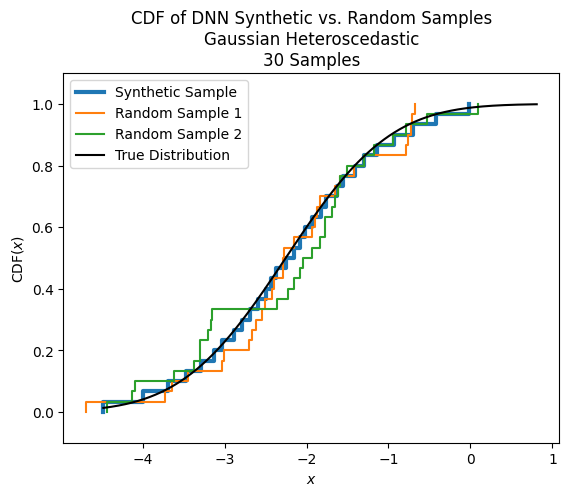

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import scipy

print(est_dist.shape)
x_min = min(np.min(data_table[0,0]), np.min(est_dist))
x_max = max(np.max(data_table[0,0]), np.max(est_dist))
x = np.linspace(x_min, x_max, num = 1000)
y = scipy.stats.norm.cdf(x, mean_rows[0], std_cols[0])

# plt.hist(data_table[0,0], density = True, alpha = 0.8)
# plt.hist(est_dist, density = True, alpha = 0.8)
# plt.ecdf(data_table[0,0])
plt.ecdf(est_dist, linewidth=3)
for _ in range(2):
    plt.ecdf(np.random.normal(mean_rows[0], std_cols[0], n))
# sample = np.random.normal(mean_rows[0], std_cols[0], n)
# plt.ecdf(sample)

plt.plot(x,y, '-', c='k')
plt.legend(["Synthetic Sample"] + [f"Random Sample {i + 1}" for i in range(2)] + ["True Distribution"])
# plt.legend(["Synthetic Sample", "Random Sample", "True Distribution"])
# plt.title(f"Gaussian Homoscedastic \n Random Sample Error = {true_error:.4f} \n Synthetic Sample Error = {est_error:.4f}")
plt.title(f"CDF of DNN Synthetic vs. Random Samples\nGaussian Heteroscedastic\n{n} Samples")
plt.xlabel("$x$")
plt.ylabel("CDF($x$)")
plt.ylim([-0.1,1.1])

In [34]:
print(len(np.nonzero(np.isnan(M_hs))[0]))
print(len(np.nonzero(~np.isnan(M_hs))[0]))

22452
92988


In [322]:
print(est_dist)

[[-0.17371179  0.78008674  0.91202266  0.92311872  0.97790006  1.07755487
   1.24919119  1.25363006  1.30928846  1.31649449  1.49700564  1.56971364
   1.68339314  1.77940215  1.80915531  1.93241014  1.9900647   2.06936932
   2.11661689  2.32401833  2.39531824  2.40019381  2.45782962  2.48018471
   2.59462926  2.64470572  2.67095257  2.87939758  3.23712639  3.26857845]
 [ 0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.        ]
 [ 0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.         

### Testing MMD with a simulated example

In [52]:
import dnn
import cross_validate_dnn as cv_dnn
from itertools import product

In [53]:
def normal_ppf(mean, std):
    return lambda q, mean = mean, std = std : norm.ppf(q, loc = mean, scale = std)

In [54]:
M = 100
N = 20
n = 30

mean_rows = np.random.uniform(-5,5,M)
# std_cols = np.random.uniform(1,5,N)
std_cols = np.ones(N)
data_table = np.zeros((M, N, n))
data_table_dict = {}
true_dists = {}
for i, j in product(range(M), range(N)):
    data = np.sort(np.random.normal(mean_rows[i], std_cols[j], n))
    data_table[i,j,:] = data
    data_table_dict[i,j] = data
    true_dists[i,j] = normal_ppf(mean_rows[i], std_cols[j])
mask = np.ones((M,N)).astype(int)
mask[0,0] = 0

data_table = data_table[:, :, :, None]
col_dists = dnn.get_col_differences(data_table, mask, "mmd", kernel = "square")

#x = np.nonzero(mask[0] == 0)[0]
#est_dist = wasserstein2_est_unit_fast(data_table, mask, 0, x, eta)[0]


20
190


In [59]:
col_dists.shape

(20, 20)

In [60]:
eta_star, _ = cv_dnn.search_eta(data_table, mask, 5, 0, col_dists, est_func = dnn.estimate_row, metric = 'mmd', range_min = 0, range_max = 50000, kernel = "square")
x = np.nonzero(mask[0] == 0)[0]
est_dist = dnn.estimate_row(data_table, mask, 0, x, col_dists, eta_star, metric = 'mmd')[0]


100%|██████████| 200/200 [00:06<00:00, 32.73trial/s, best loss: 1.9103840043653464]


In [61]:
est_dist = est_dist.flatten()

(540,)


(-0.1, 1.1)

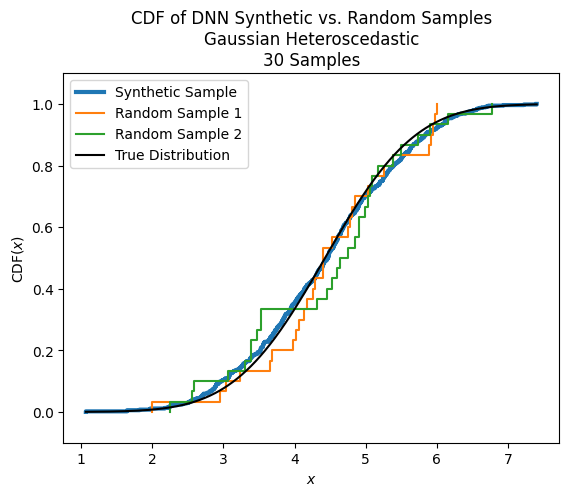

In [62]:
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import scipy

print(est_dist.shape)
x_min = min(np.min(data_table[0,0]), np.min(est_dist))
x_max = max(np.max(data_table[0,0]), np.max(est_dist))
x = np.linspace(x_min, x_max, num = 1000)
y = scipy.stats.norm.cdf(x, mean_rows[0], std_cols[0])

# plt.hist(data_table[0,0], density = True, alpha = 0.8)
# plt.hist(est_dist, density = True, alpha = 0.8)
# plt.ecdf(data_table[0,0])
plt.ecdf(est_dist, linewidth=3)
for _ in range(2):
    plt.ecdf(np.random.normal(mean_rows[0], std_cols[0], n))
# sample = np.random.normal(mean_rows[0], std_cols[0], n)
# plt.ecdf(sample)

plt.plot(x,y, '-', c='k')
plt.legend(["Synthetic Sample"] + [f"Random Sample {i + 1}" for i in range(2)] + ["True Distribution"])
# plt.legend(["Synthetic Sample", "Random Sample", "True Distribution"])
# plt.title(f"Gaussian Homoscedastic \n Random Sample Error = {true_error:.4f} \n Synthetic Sample Error = {est_error:.4f}")
plt.title(f"CDF of DNN Synthetic vs. Random Samples\nGaussian Heteroscedastic\n{n} Samples")
plt.xlabel("$x$")
plt.ylabel("CDF($x$)")
plt.ylim([-0.1,1.1])

### Cross-validation for Heartsteps data

In this section, we will do cross-validation for finding the best value for eta as well as experiment with different partitioning strategies, values of k during k fold, testset_size, k, and row

In [42]:
import random
from hyperopt import fmin, tpe, hp, STATUS_OK, Trials
from itertools import product


In [ ]:
A_hs

In [98]:
# looking for eta range
diffs = get_col_differences(M_hs_40, A_hs_40, "mmd", kern = exponential_kernel)
nonnans = np.nonzero(~np.isnan(diffs))

C:\Users\Caleb\AppData\Local\Temp\ipykernel_26852\1920898457.py:163: RuntimeWarning: Mean of empty slice
  diffs =  (1 / (n * (n - 1)) * (np.nanmean(sum_h, axis = 2))) # average over users, unobserved entries are already nan


In [104]:
np.nanmin(diffs[~np.isinf(diffs)])

-0.3408921264994255

In [123]:
def search_eta(data_table, mask, k, row, col_dists, est_func, metric, negate_mask = False):
    """
    Search for an optimal eta using cross validation on
    the observed data.
    """
    def obj(eta):
    #     return evaluate_eta(data_table, mask, k, eta)
        return cross_validate_row_dnn(data_table, mask, row, k, eta, col_dists, est_func, error_metric = metric, negate_mask = negate_mask)
    trials = Trials()
    best_eta = fmin(fn=obj, verbose = True, space=hp.uniform('eta', -0.3, 0.3), algo=tpe.suggest, max_evals=200, trials = trials)
    return best_eta['eta'], trials

    


def test_w2_cv_heartsteps_row(M_hs, A_hs, testset_size, k, row, negate_mask = False):
    """
    Evaluate test error on a row of Heartsteps data using cv-tuned eta and Wasserstein_2
    metric
    """
    np.random.seed(seed = 42)
    #col_inds = np.arange(len(A_hs[0]))
    obvs_inds_x = np.nonzero(A_hs[row] == 1)[0]

    # shuffle the x and y coordinates in the same way to maintain valid coords
    ##shuf_inds = np.arange(len(obvs_inds_x))
    np.random.shuffle(obvs_inds_x)
    ##shuf_obvs_inds = np.array((obvs_inds_x[shuf_inds], obvs_inds_y[shuf_inds]))

    test_ind = int(testset_size * len(obvs_inds_x))
    #test_ind = int(testset_size * len(M_hs[0]))

    #rnd_inds = random.sample(range(len(M_hs[0])), test_ind)

    #test_set_M = M_hs[:, rnd_inds].copy()
    #test_set_A = A_hs[:, rnd_inds].copy()
    #if len(np.nonzero(test_set_A == 1)[0]) < 1:
    #    print("Test set was empty")
    #    return

    #train_set_M = np.delete(M_hs, rnd_inds, axis = 1)
    #train_set_A = np.delete(A_hs, rnd_inds, axis = 1)
    # take testset_size number of obvs for test set
    tst_obs = obvs_inds_x[:test_ind]
    #train_obs = (shuf_obvs_inds[0][test_ind:], shuf_obvs_inds[1][test_ind:])
    M_hs = np.sort(M_hs, axis = -1)
    A_train = A_hs.copy()
    M_train = M_hs.copy()
    # during training, the tst obs and their columns are unobserved
    A_train[:, tst_obs] = 0
    M_train[:, tst_obs] = np.nan
    #print(A_train.shape)
    # CURRENT STRATEGY: Tune eta on only the training set, then use the entire data set to
    # find neighborhood for unkown values
    eta, trials = search_eta(M_train, A_train, k, row, wasserstein2_est_unit_fast, 'wasserstein2', negate_mask = negate_mask)

    # this is ground truth
    test_M = M_hs[row, tst_obs]
    #print(test_M.shape)

    # this is the estimate
    est_dist = wasserstein2_est_unit_fast(M_hs[:, tst_obs], A_hs[:,tst_obs], row, np.arange(0, len(tst_obs)), eta, negate_mask = negate_mask)#[tst_obs]
    #print(est_dist.shape)
    ws2_error = avg_wasserstein2_dist(est_dist, test_M)
    print("Avg Wasserstein Error: " + str(ws2_error))
    return ws2_error, trials

def test_w2_hs_whole(M_hs, A_hs, testset_size, k, row):
    """
    Compute the test error of the test set (testset_size proportion of the end of the matrix)

    Current strategy: tune eta using train set, only find neighbors within the test set 
    """
    test_ind = int(testset_size * len(M_hs[0]))
    M_hs = np.sort(M_hs, axis = -1)
    
    test_M = M_hs[:, -test_ind:]
    test_A = A_hs[:, -test_ind:]
    train_M = M_hs[:, :test_ind]
    train_A = A_hs[:, :test_ind]

    # sample split
    dist_train_A = train_A.copy()
    dist_train_A[row] = 0
    col_dists = get_col_differences(train_M, dist_train_A)
    eta_star, trials = search_eta(train_M, train_A, k, row, col_dists, estimate_row, "wasserstein2")

    test_inds = np.nonzero(A_hs[row] == 1)[0]
    test_inds = test_inds[test_inds >= (len(A_hs[row]) - test_ind)]
    dist_A = A_hs.copy()
    dist_A[row] = 0 # mask out row when computing distance
    col_dists = get_col_differences(M_hs, dist_A, "wasserstein2")
    #print(col_dists.shape)
    estimates = estimate_row(M_hs, A_hs, row, test_inds, col_dists, eta_star, "wasserstein2")
    est_test_inds = estimates[test_inds]
    ground_truth = M_hs[row, test_inds].squeeze(axis = -1)

    ws2_error = avg_wasserstein2_dist(est_test_inds, ground_truth)
    print("Avg Wasserstein Error: " + str(ws2_error))
    return ws2_error, trials

def test_w2_hs_end(M_hs, A_hs, testset_size, k, row):
    """
    Compute the test error of the test set (testset_size proportion of the end of the matrix)

    Current strategy: tune eta using train set, only find neighbors within the test set 
    """
    test_ind = int(testset_size * len(M_hs[0]))
    M_hs = np.sort(M_hs, axis = -1)
    
    test_M = M_hs[:, -test_ind:]
    test_A = A_hs[:, -test_ind:]
    train_M = M_hs[:, :test_ind]
    train_A = A_hs[:, :test_ind]

    # sample split
    dist_train_A = train_A.copy()
    dist_train_A[row] = 0
    col_dists = get_col_differences(train_M, dist_train_A)
    eta_star, trials = search_eta(train_M, train_A, k, row, col_dists, estimate_row, "wasserstein2")

    test_inds = np.nonzero(test_A[row] == 1)[0]
    dist_A = test_A.copy()
    dist_A[row] = 0 # mask out row when computing distance
    col_dists = get_col_differences(test_M, dist_A, "wasserstein2")
    #print(col_dists.shape)
    estimates = estimate_row(test_M, test_A, row, test_inds, col_dists, eta_star, "wasserstein2")
    est_test_inds = estimates[test_inds]
    ground_truth = test_M[row, test_inds].squeeze(axis = -1)

    ws2_error = avg_wasserstein2_dist(est_test_inds, ground_truth)
    print("Avg Wasserstein Error: " + str(ws2_error))
    return ws2_error, trials



def test_mmd_hs_whole(M_hs, A_hs, testset_size, k, row, kernel):
    """
    Compute the test error of the test set (testset_size proportion of the end of the matrix)

    Current strategy: tune eta using train set, only find neighbors within the test set 
    """
    test_ind = int(testset_size * len(M_hs[0]))
    M_hs = np.sort(M_hs, axis = -1)
    
    test_M = M_hs[:, -test_ind:]
    test_A = A_hs[:, -test_ind:]
    train_M = M_hs[:, :test_ind]
    train_A = A_hs[:, :test_ind]

    # sample split
    dist_train_A = train_A.copy()
    dist_train_A[row] = 0
    col_dists = get_col_differences(train_M, dist_train_A, metric = "mmd", kern=exponential_kernel)
    eta_star, trials = search_eta(train_M, train_A, k, row, col_dists, estimate_row, "mmd")

    test_inds = np.nonzero(A_hs[row] == 1)[0]
    test_inds = test_inds[test_inds >= (len(A_hs[row]) - test_ind)]
    dist_A = A_hs.copy()
    dist_A[row] = 0 # mask out row when computing distance
    col_dists = get_col_differences(M_hs, dist_A, "mmd", kern=exponential_kernel)
    #print(col_dists.shape)
    estimates = estimate_row(M_hs, A_hs, row, test_inds, col_dists, eta_star, "mmd")
    #est_test_inds = estimates[test_inds]
    ground_truth = M_hs[row]

    mmd_error = avg_mmd_distance(estimates, ground_truth, test_inds, kernel = kernel)
    print("Avg MMD Error: " + str(mmd_error))
    return mmd_error, trials

def test_mmd_hs_end(M_hs, A_hs, testset_size, k, row, kernel):
    """
    Compute the test error of the test set (testset_size proportion of the end of the matrix)

    Current strategy: tune eta using train set, only find neighbors within the test set 
    """
    test_ind = int(testset_size * len(M_hs[0]))
    #M_hs = np.sort(M_hs, axis = -1)
    
    test_M = M_hs[:, -test_ind:]
    test_A = A_hs[:, -test_ind:]
    train_M = M_hs[:, :test_ind]
    train_A = A_hs[:, :test_ind]

    # sample split
    dist_train_A = train_A.copy()
    dist_train_A[row] = 0
    # TODO: fix kernel name vs kernel function discrepancy
    col_dists = get_col_differences(train_M, dist_train_A, metric = "mmd", kern = exponential_kernel)
    eta_star, trials = search_eta(train_M, train_A, k, row, col_dists, estimate_row, "mmd")

    test_inds = np.nonzero(test_A[row] == 1)[0]
    dist_A = test_A.copy()
    dist_A[row] = 0 # mask out row when computing distance
    col_dists = get_col_differences(test_M, dist_A, "mmd", kern = exponential_kernel)
    #print(col_dists.shape)
    estimates = estimate_row(test_M, test_A, row, test_inds, col_dists, eta_star, "mmd")
    #est_test_inds = estimates[test_inds]
    ground_truth = test_M[row]

    mmd_error = avg_mmd_distance(estimates, ground_truth, test_inds, kernel = kernel)
    print("Avg MMD Error: " + str(mmd_error))
    return mmd_error, trials




In [1]:
%load_ext autoreload
%autoreload 2

In [3]:
import numpy as np

In [4]:
# load in the data sets
A_hs = np.load("heartsteps_mask.npy")
M_hs = np.load("heartsteps_data.npy")
M_hs = M_hs[:, :, :, None]

(37, 200, 12, 1)

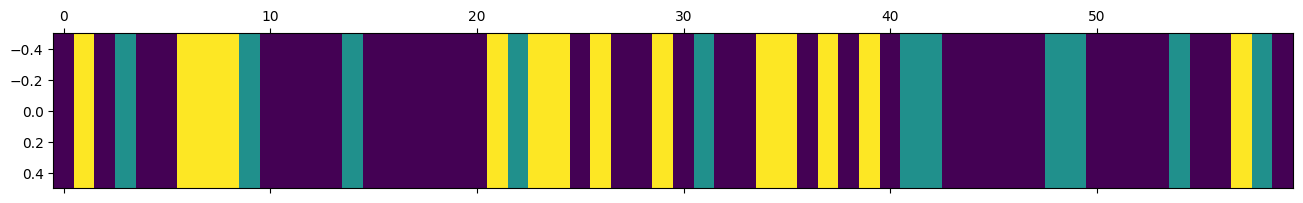

In [7]:
# we take the first 40 days of the trials to maintain user density
M_hs_40 = M_hs[:, 0:200]
A_hs_40 = A_hs[:, 0:200]
matshow(A_hs_40[29:30, -60:], aspect = "auto")
M_hs_40.shape

In [242]:
test_ind = int(0.3 * len(M_hs_40[0]))
test_M = M_hs_40[:, -test_ind:]
test_A = A_hs_40[:, -test_ind:]
dist_A = test_A.copy()
dist_A[33] = 0
col_dists = get_col_differences(test_M, dist_A, "wasserstein2")
print("shape ") 
print(test_M.shape)
test_inds = np.nonzero(test_A[33] == 1)[0]
estimate_row(test_M, test_A, 33, test_inds, col_dists, 10000, "wasserstein2")

shape 
(37, 60, 12)
3
neighbor
(60, 60)
(37, 60, 12)
jnn
(60,)
5
neighbor
(60, 60)
(37, 60, 12)
jnn
(60,)
9
neighbor
(60, 60)
(37, 60, 12)
jnn
(60,)
12
neighbor
(60, 60)
(37, 60, 12)
jnn
(60,)
20
neighbor
(60, 60)
(37, 60, 12)
jnn
(60,)
23
neighbor
(60, 60)
(37, 60, 12)
jnn
(60,)
30
neighbor
(60, 60)
(37, 60, 12)
jnn
(60,)
31
neighbor
(60, 60)
(37, 60, 12)
jnn
(60,)
32
neighbor
(60, 60)
(37, 60, 12)
jnn
(60,)
42
neighbor
(60, 60)
(37, 60, 12)
jnn
(60,)
43
neighbor
(60, 60)
(37, 60, 12)
jnn
(60,)
45
neighbor
(60, 60)
(37, 60, 12)
jnn
(60,)
48
neighbor
(60, 60)
(37, 60, 12)
jnn
(60,)
53
neighbor
(60, 60)
(37, 60, 12)
jnn
(60,)
55
neighbor
(60, 60)
(37, 60, 12)
jnn
(60,)


C:\Users\Caleb\AppData\Local\Temp\ipykernel_30228\3839937845.py:24: RuntimeWarning: Mean of empty slice
  diffs = np.nanmean((Z_cp.swapaxes(0, 1)[:, None, :,  :] - Z_cp.swapaxes(0, 1))**2, axis = -1)
C:\Users\Caleb\AppData\Local\Temp\ipykernel_30228\3839937845.py:27: RuntimeWarning: Mean of empty slice
  diffs = np.nanmean(diffs, axis = -1)


array([[        nan,         nan,         nan,         nan,         nan,
                nan,         nan,         nan,         nan,         nan,
                nan,         nan],
       [        nan,         nan,         nan,         nan,         nan,
                nan,         nan,         nan,         nan,         nan,
                nan,         nan],
       [        nan,         nan,         nan,         nan,         nan,
                nan,         nan,         nan,         nan,         nan,
                nan,         nan],
       [ 4.75      ,  9.5       ,  3.75      , 14.875     ,  1.625     ,
         3.625     ,  3.375     , 18.875     ,  4.375     , 20.375     ,
        43.875     , 49.875     ],
       [        nan,         nan,         nan,         nan,         nan,
                nan,         nan,         nan,         nan,         nan,
                nan,         nan],
       [18.77777778, 26.77777778, 16.66666667, 28.22222222, 11.22222222,
         5.55555556,  

In [198]:
np.nansum(M_hs_40[33])

31844.0

In [113]:
mmd_err, mmd_trials = test_mmd_hs_end(M_hs_40, A_hs_40, testset_size = 0.30, k =5, row = 33, kernel = "exponential")

yes neighbors                                          
yes neighbors                                          
yes neighbors                                          
yes neighbors                                          
yes neighbors                                          
yes neighbors                                          
yes neighbors                                          
yes neighbors                                          
yes neighbors                                          
yes neighbors                                          
yes neighbors                                          
yes neighbors                                          
yes neighbors                                          
yes neighbors                                          
yes neighbors                                          
yes neighbors                                          
yes neighbors                                          
No neighbors                                    

C:\Users\Caleb\AppData\Local\Temp\ipykernel_26852\344994502.py:41: RuntimeWarning: Mean of empty slice
  diffs =  (1 / (n * (n - 1)) * (np.nanmean(sum_h, axis = 2))) # average over users, unobserved entries are already nan


No neighbors                                                                      
No neighbors                                                                      
No neighbors                                                                      
yes neighbors                                                                      
yes neighbors                                                                      
yes neighbors                                                                      
yes neighbors                                                                      
yes neighbors                                                                      
yes neighbors                                                                      
yes neighbors                                                                      
yes neighbors                                                                      
yes neighbors                                                                  

In [348]:
err, trials = test_w2_hs_whole(M_hs_40, A_hs_40, testset_size = 0.30, k = 5, row = 33)


 25%|██▌       | 50/200 [00:00<00:00, 242.37trial/s, best loss: 226.66360879629627]

C:\Users\Caleb\AppData\Local\Temp\ipykernel_30228\3132602101.py:24: RuntimeWarning: Mean of empty slice
  diffs = np.nanmean((Z_cp.swapaxes(0, 1)[:, None, :,  :] - Z_cp.swapaxes(0, 1))**2, axis = -1)
C:\Users\Caleb\AppData\Local\Temp\ipykernel_30228\3132602101.py:27: RuntimeWarning: Mean of empty slice
  diffs = np.nanmean(diffs, axis = -1)
C:\Users\Caleb\AppData\Local\Temp\ipykernel_30228\3132602101.py:124: RuntimeWarning: Mean of empty slice
  est = np.nanmean(Z_cp[i, j_nn], axis = 0)

C:\Users\Caleb\AppData\Local\Temp\ipykernel_30228\3132602101.py:7: RuntimeWarning: Mean of empty slice
  return np.nanmean((np.nanmean((Y_i - Y_j)**2, axis = 1)), axis = 0)



100%|██████████| 200/200 [00:00<00:00, 250.38trial/s, best loss: 226.66360879629627]
Avg Wasserstein Error: 1524.0523662823705


Text(0, 0.5, 'Avg. 5-fold $MMD_k^2$ error')

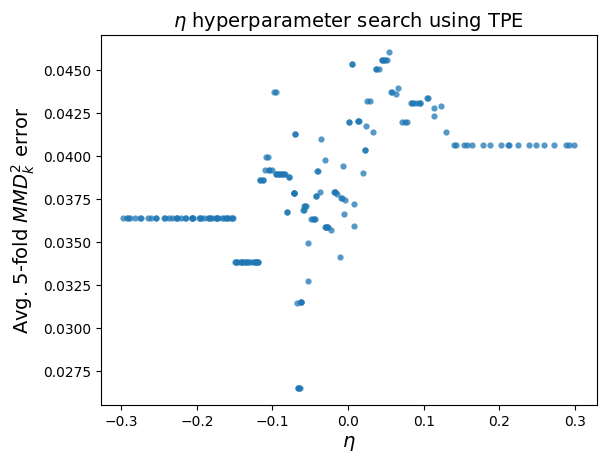

In [116]:
f, ax = plt.subplots(1)
xs = [t['misc']['vals']['eta'] for t in mmd_trials.trials]
ys = [t['result']['loss'] for t in mmd_trials.trials]
ax.scatter(xs, ys, s=20, linewidth=0.01, alpha=0.75)
ax.set_title('$\eta$ hyperparameter search using TPE', fontsize=14)
ax.set_xlabel('$\eta$', fontsize=14)
ax.set_ylabel('Avg. 5-fold $MMD_k^2$ error', fontsize=14)

Text(0, 0.5, 'Avg. 5-fold $Wasserstein_2^2$ error')

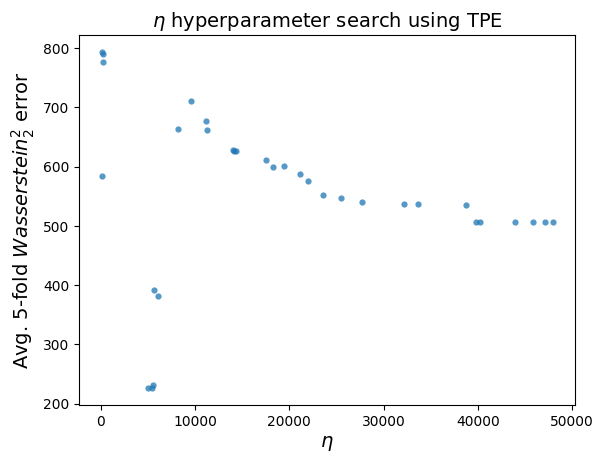

In [349]:
f, ax = plt.subplots(1)
xs = [t['misc']['vals']['eta'] for t in trials.trials]
ys = [t['result']['loss'] for t in trials.trials]
ax.scatter(xs, ys, s=20, linewidth=0.01, alpha=0.75)
ax.set_title('$\eta$ hyperparameter search using TPE', fontsize=14)
ax.set_xlabel('$\eta$', fontsize=14)
ax.set_ylabel('Avg. 5-fold $Wasserstein_2^2$ error', fontsize=14)

In [16]:
import cross_validate_dnn as cv_dnn

In [18]:
row_num_mmd = []
error_mmd_exp = []
error_mmd_sq = []
error_mmd_lin = []
for i in range(37):
  print("Row " + str(i))
  row_num_mmd.append(i)
  err, _ = cv_dnn.test_mmd_hs_end(M_hs_40, A_hs_40, testset_size = 0.3, k = 5, row = i, kernel = "exponential")
  error_mmd_exp.append(err)
  err, _ = cv_dnn.test_mmd_hs_end(M_hs_40, A_hs_40, testset_size = 0.3, k = 5, row = i, kernel = "square")
  error_mmd_sq.append(err)
  err, _ = cv_dnn.test_mmd_hs_end(M_hs_40, A_hs_40, testset_size = 0.3, k = 5, row = i, kernel = "linear")
  error_mmd_lin.append(err)

Row 0
  3%|▎         | 6/200 [00:00<00:03, 57.14trial/s, best loss: 0.36768961462684374]

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn.py:231: RuntimeWarning: Mean of empty slice
  diffs =  (1 / (n * (n - 1)) * (np.nanmean(sum_h, axis = 2))) # average over users, unobserved entries are already nan


100%|██████████| 200/200 [00:02<00:00, 68.29trial/s, best loss: 0.3380615109407875] 
Test Inds
[ 5  6  7  8 11 14 15 24 31 32 34]
11
inds
[ 5  6  7  8 11 14 15 24 31 32 34]
Avg MMD Error: 0.03947996115999412
100%|██████████| 200/200 [00:02<00:00, 99.18trial/s, best loss: 0.39265375717959905] 
Test Inds
[ 5  6  7  8 11 14 15 24 31 32 34]
11
inds
[ 5  6  7  8 11 14 15 24 31 32 34]
Avg MMD Error: 35040046.11921919
100%|██████████| 200/200 [00:02<00:00, 80.16trial/s, best loss: 0.39127618841719]
Test Inds
[ 5  6  7  8 11 14 15 24 31 32 34]
11
inds
[ 5  6  7  8 11 14 15 24 31 32 34]
Avg MMD Error: 634.5059388428109
Row 1
100%|██████████| 200/200 [00:01<00:00, 108.31trial/s, best loss: 0.10499202391140046]
Test Inds
[ 0  3 14 26]
4
inds
[ 0  3 14 26]
Avg MMD Error: 0.00854287556415212
100%|██████████| 200/200 [00:01<00:00, 133.36trial/s, best loss: 0.19434929742919732]
Test Inds
[ 0  3 14 26]
4
inds
[ 0  3 14 26]
Avg MMD Error: 700466866.7370515
100%|██████████| 200/200 [00:01<00:00, 124.35t

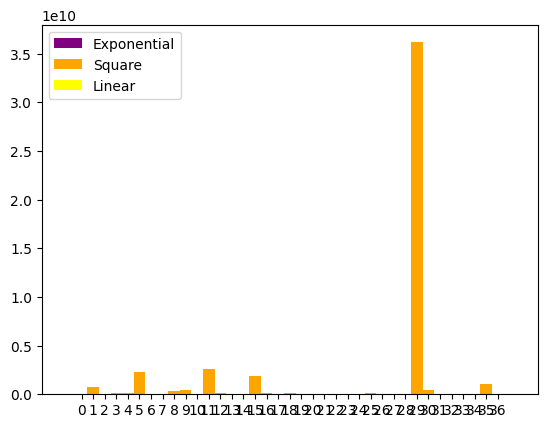

In [19]:
x = np.arange(37)
plt.bar(x - 1, error_mmd_exp, width = 1, color = 'purple')
plt.bar(x, error_mmd_sq, width = 1, color = "orange")
plt.bar(x + 1, error_mmd_lin, width = 1, color = "yellow")

plt.xticks(x, row_num_mmd)

plt.legend(["Exponential", "Square", "Linear"])

In [344]:
row_num = []
error = []
for i in range(37):
  print("Row " + str(i))
  row_num.append(i)
  err = test_w2_hs_whole(M_hs_40, A_hs_40, testset_size = 0.4, k = 5, row = i)
  error.append(err)

Row 0
  0%|          | 0/200 [00:00<?, ?trial/s, best loss=?]

  7%|▋         | 14/200 [00:00<00:01, 139.05trial/s, best loss: 11298.723761518208]

C:\Users\Caleb\AppData\Local\Temp\ipykernel_30228\3132602101.py:24: RuntimeWarning: Mean of empty slice
  diffs = np.nanmean((Z_cp.swapaxes(0, 1)[:, None, :,  :] - Z_cp.swapaxes(0, 1))**2, axis = -1)
C:\Users\Caleb\AppData\Local\Temp\ipykernel_30228\3132602101.py:27: RuntimeWarning: Mean of empty slice
  diffs = np.nanmean(diffs, axis = -1)
C:\Users\Caleb\AppData\Local\Temp\ipykernel_30228\3132602101.py:124: RuntimeWarning: Mean of empty slice
  est = np.nanmean(Z_cp[i, j_nn], axis = 0)

C:\Users\Caleb\AppData\Local\Temp\ipykernel_30228\3132602101.py:7: RuntimeWarning: Mean of empty slice
  return np.nanmean((np.nanmean((Y_i - Y_j)**2, axis = 1)), axis = 0)



100%|██████████| 200/200 [00:00<00:00, 237.93trial/s, best loss: 11298.723761518208]
Avg Wasserstein Error: 5706.838007298595
Row 1
100%|██████████| 200/200 [00:00<00:00, 305.13trial/s, best loss: 10085.866346816441]
Avg Wasserstein Error: 12564.642855927228
Row 2
100%|██████████| 200/200 [00:00<00:00, 284.78trial/s, best loss: 353.4011074340545]
Avg Wasserstein Error: 4589.630683376814
Row 3
100%|██████████| 200/200 [00:00<00:00, 284.15trial/s, best loss: 19524.972327860254]
Avg Wasserstein Error: 6833.750147721105
Row 4
100%|██████████| 200/200 [00:00<00:00, 301.78trial/s, best loss: 5919.553491512344]
Avg Wasserstein Error: 16904.37353946208
Row 5
100%|██████████| 200/200 [00:00<00:00, 354.20trial/s, best loss: 2575.385648148148]
Avg Wasserstein Error: 11824.828703687748
Row 6
100%|██████████| 200/200 [00:00<00:00, 307.54trial/s, best loss: 6112.474269113905]
Avg Wasserstein Error: 1494.4415048419446
Row 7
100%|██████████| 200/200 [00:00<00:00, 222.74trial/s, best loss: 10740.118226

In [345]:
unit_error = []
for i in range(len(error)):
  unit_error.append(error[i][0])

In [119]:
unit_error_mmd = []
for i in range(len(error_mmd)):
  unit_error_mmd.append(error_mmd[i][0])

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


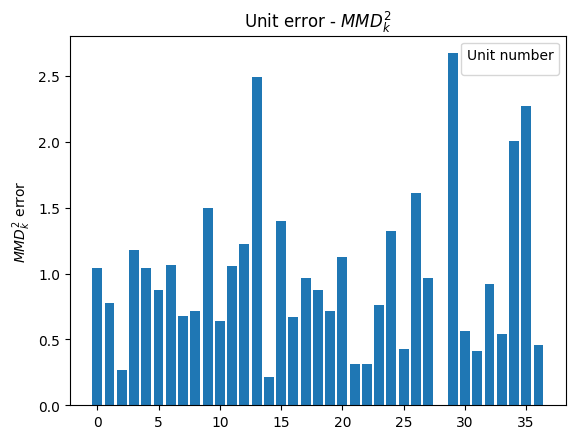

In [120]:
fig, ax = plt.subplots()

ax.bar(row_num_mmd, unit_error_mmd)

ax.set_ylabel('$MMD_k^2$ error')
ax.set_title('Unit error - $MMD_k^2$')
ax.legend(title='Unit number')

plt.show()

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


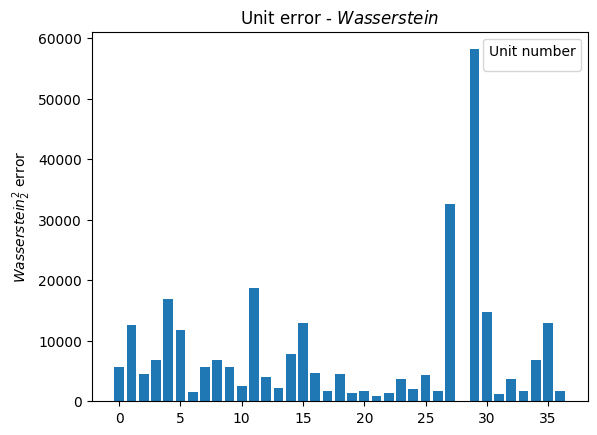

In [347]:
fig, ax = plt.subplots()

ax.bar(row_num, unit_error)

ax.set_ylabel('$Wasserstein_2^2$ error')
ax.set_title('Unit error - $Wasserstein$')
ax.legend(title='Unit number')

plt.show()

In [53]:
row_num = []
error = []
for i in range(37):
  print("Row " + str(i))
  row_num.append(i)
  err = test_w2_cv_heartsteps_row(M_hs, A_hs, testset_size = 0.4, k = 5, row = i)
  error.append(err)

Row 0
  0%|          | 0/75 [00:00<?, ?trial/s, best loss=?]

C:\Users\Caleb\AppData\Local\Temp\ipykernel_17928\1544488582.py:33: RuntimeWarning: Mean of empty slice
  w_2 = np.nanmean((Y_i - Y_js) ** 2, axis = -1)

C:\Users\Caleb\AppData\Local\Temp\ipykernel_17928\1544488582.py:71: RuntimeWarning: Mean of empty slice
  scores[cols] = np.nanmean(w2_scores, axis = 2)



100%|██████████| 75/75 [00:33<00:00,  2.22trial/s, best loss: 7005.134588268178]
Avg Wasserstein Error: 7956.217073449248
Row 1
No observed entries                                                              
100%|██████████| 75/75 [00:35<00:00,  2.13trial/s, best loss: 10617.543519156688]
Avg Wasserstein Error: 9736.252701564184
Row 2
100%|██████████| 75/75 [00:35<00:00,  2.12trial/s, best loss: 3359.7720391401076]
Avg Wasserstein Error: 4601.874399149829
Row 3
100%|██████████| 75/75 [00:37<00:00,  2.02trial/s, best loss: 12185.140722193637]
Avg Wasserstein Error: 20295.278993584237
Row 4
100%|██████████| 75/75 [00:35<00:00,  2.09trial/s, best loss: 6111.002241843262]
Avg Wasserstein Error: 3772.9331932271034
Row 5
No observed entries                                                              
100%|██████████| 75/75 [00:35<00:00,  2.10trial/s, best loss: 2361.4903949102263]
Avg Wasserstein Error: 12916.32245826611
Row 6
100%|██████████| 75/75 [00:33<00:00,  2.21trial/s, best loss: 

C:\Users\Caleb\AppData\Local\Temp\ipykernel_17928\1544488582.py:107: RuntimeWarning: Mean of empty slice
  barycenters[j] = np.nanmean(X_cp[i, NN_cols[j]], axis = 0)



100%|██████████| 75/75 [00:55<00:00,  1.35trial/s, best loss: 8670.483248182889]
Avg Wasserstein Error: 8852.538985661413
Row 17
No observed entries                                                              
100%|██████████| 75/75 [00:57<00:00,  1.29trial/s, best loss: 1656.3279971522766]
Avg Wasserstein Error: 4747.0809740572495
Row 18
100%|██████████| 75/75 [00:57<00:00,  1.31trial/s, best loss: 5242.29851950341] 
Avg Wasserstein Error: 6104.684151058364
Row 19
100%|██████████| 75/75 [00:58<00:00,  1.29trial/s, best loss: 933.5386785331955]
Avg Wasserstein Error: 2195.9748067863343
Row 20
No observed entries                                                              
100%|██████████| 75/75 [00:57<00:00,  1.31trial/s, best loss: 2982.091451381045]
Avg Wasserstein Error: 13615.595044308777
Row 21
No observed entries                                                              
100%|██████████| 75/75 [00:59<00:00,  1.25trial/s, best loss: 1399.0701454476998]
Avg Wasserstein Error: 

In [33]:
test_w2_cv_heartsteps_row(M_hs, A_hs, testset_size = 0.4, k = 5, row = 33)

C:\Users\Caleb\AppData\Local\Temp\ipykernel_17928\1544488582.py:33: RuntimeWarning: Mean of empty slice
  w_2 = np.nanmean((Y_i - Y_js) ** 2, axis = -1)
C:\Users\Caleb\AppData\Local\Temp\ipykernel_17928\1544488582.py:71: RuntimeWarning: Mean of empty slice
  scores[cols] = np.nanmean(w2_scores, axis = 2)
C:\Users\Caleb\AppData\Local\Temp\ipykernel_17928\1544488582.py:7: RuntimeWarning: Mean of empty slice
  return np.nanmean((np.nanmean((Y_i - Y_j)**2, axis = 1)), axis = 0)


Avg Wasserstein Error: 892.9374654474157


892.9374654474157

In [60]:
tst_size = []
error_whole = []
error_end = []
for i in np.linspace(0.1, 0.9, num=9):
  print("Test set size " + str(i))
  tst_size.append(i)
  err_end, trials = test_w2_hs_end(M_hs_40, A_hs_40, testset_size = i, k = 5, row = 33)
  error_end.append(err_end)
  err_whole, trials = test_w2_hs_whole(M_hs_40, A_hs_40, testset_size=i, k = 5, row = 33)
  error_whole.append(err_whole)


Test set size 0.1
 14%|█▎        | 27/200 [00:00<00:00, 258.85trial/s, best loss: 817.7548611111113]

C:\Users\Caleb\AppData\Local\Temp\ipykernel_26852\3320870942.py:27: RuntimeWarning: Mean of empty slice
  diffs = np.nanmean((Z_cp.swapaxes(0, 1)[:, None, :,  :] - Z_cp.swapaxes(0, 1))**2, axis = -1)
C:\Users\Caleb\AppData\Local\Temp\ipykernel_26852\3320870942.py:30: RuntimeWarning: Mean of empty slice
  diffs = np.nanmean(diffs, axis = -1)
C:\Users\Caleb\AppData\Local\Temp\ipykernel_26852\3320870942.py:140: RuntimeWarning: Mean of empty slice
  est = np.nanmean(Z_cp[i, j_nn], axis = 0).flatten()

C:\Users\Caleb\AppData\Local\Temp\ipykernel_26852\3320870942.py:7: RuntimeWarning: Mean of empty slice
  return np.nanmean((np.nanmean((Y_i - Y_j)**2, axis = 1)), axis = 0)



100%|██████████| 200/200 [00:01<00:00, 174.72trial/s, best loss: 817.7548611111113]
Avg Wasserstein Error: 6346.89699074074
100%|██████████| 200/200 [00:01<00:00, 134.22trial/s, best loss: 817.7548611111113]
Avg Wasserstein Error: 3830.5128122921465
Test set size 0.2
100%|██████████| 200/200 [00:01<00:00, 125.04trial/s, best loss: 759.2366952475435]
Avg Wasserstein Error: 2946.13998380918
100%|██████████| 200/200 [00:01<00:00, 132.46trial/s, best loss: 759.2366952475435]
Avg Wasserstein Error: 2387.8389754575605
Test set size 0.30000000000000004
100%|██████████| 200/200 [00:01<00:00, 110.14trial/s, best loss: 520.0989473978892]
Avg Wasserstein Error: 2502.6634894617314
100%|██████████| 200/200 [00:01<00:00, 138.52trial/s, best loss: 520.0989473978892]
Avg Wasserstein Error: 2191.070045087409
Test set size 0.4
100%|██████████| 200/200 [00:01<00:00, 103.39trial/s, best loss: 332.4915541409465]
Avg Wasserstein Error: 2651.1470546570317
100%|██████████| 200/200 [00:02<00:00, 92.61trial/s, 

In [8]:
import dnn
import cross_validate_dnn as cv_dnn

In [13]:
tst_size_mmd = []
error_whole_mmd = []
error_end_mmd = []
for i in np.linspace(0.1, 0.9, num=9):
  print("Test set size " + str(i))
  tst_size_mmd.append(i)
  err_end, trials = cv_dnn.test_mmd_hs_end(M_hs_40, A_hs_40, testset_size = i, k = 5, row = 14, kernel = "exponential")
  error_end_mmd.append(err_end)
  err_whole, trials = cv_dnn.test_mmd_hs_whole(M_hs_40, A_hs_40, testset_size=i, k = 5, row = 14, kernel = "exponential")
  error_whole_mmd.append(err_whole)

Test set size 0.1
 37%|███▋      | 74/200 [00:00<00:00, 350.27trial/s, best loss: 0.09398251747050386]

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn.py:231: RuntimeWarning: Mean of empty slice
  


100%|██████████| 200/200 [00:00<00:00, 330.34trial/s, best loss: 0.09398251747050386]
Test Inds
[]
0
100%|██████████| 200/200 [00:00<00:00, 308.81trial/s, best loss: 0.09398251747050386]
Test set size 0.2
100%|██████████| 200/200 [00:01<00:00, 193.83trial/s, best loss: 0.12970500699050674]
Test Inds
[ 3 15]
2
inds
[ 3 15]
Avg MMD Error: 0.03469203670580828
100%|██████████| 200/200 [00:01<00:00, 170.80trial/s, best loss: 0.12970500699050674]
inds
[163 175]
Avg MMD Error: 0.009566314819154209
Test set size 0.30000000000000004
100%|██████████| 200/200 [00:01<00:00, 196.44trial/s, best loss: 0.11476375833285046]
Test Inds
[ 7 23 35]
3
inds
[ 7 23 35]
Avg MMD Error: 0.044768083994421524
100%|██████████| 200/200 [00:01<00:00, 140.88trial/s, best loss: 0.11476375833285046]
inds
[147 163 175]
Avg MMD Error: 0.006107699658406444
Test set size 0.4
100%|██████████| 200/200 [00:01<00:00, 107.22trial/s, best loss: 0.16306275934502362]
Test Inds
[ 5 10 14 15 16 27 43 55]
8
inds
[ 5 10 14 15 16 27 43

Text(0, 0.5, '$MMD_k^2$ Distance')

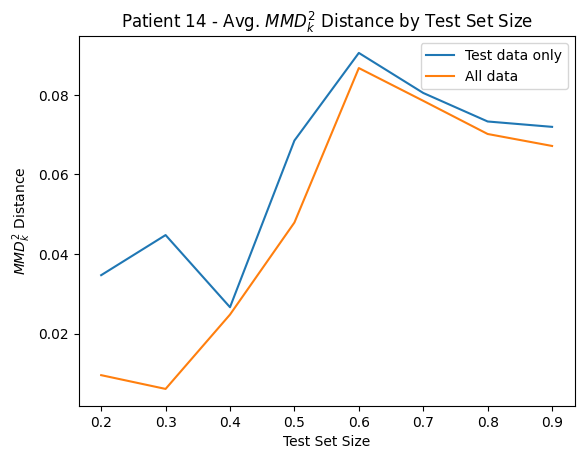

In [14]:
plt.plot(tst_size_mmd, error_end_mmd, label = 'Test data only')
plt.plot(tst_size_mmd, error_whole_mmd, label = "All data")
plt.title("Patient 14 - Avg. $MMD_k^2$ Distance by Test Set Size")
plt.legend()
plt.xlabel("Test Set Size")
plt.ylabel("$MMD_k^2$ Distance")

Text(0, 0.5, '$Wasserstein_2^2$ Distance')

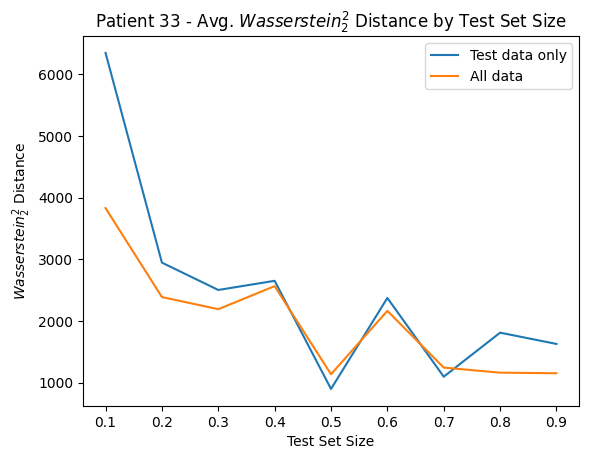

In [63]:
plt.plot(tst_size, error_end, label = 'Test data only')
plt.plot(tst_size, error_whole, label = "All data")
plt.title("Patient 33 - Avg. $Wasserstein_2^2$ Distance by Test Set Size")
plt.legend()
plt.xlabel("Test Set Size")
plt.ylabel("$Wasserstein_2^2$ Distance")

In [411]:
# get list of divisors for measurements
partitions = []
def divisors(n):
    divs = [1]
    for i in range(2,int(math.sqrt(n))+1):
        if n%i == 0:
            divs.extend([i,n//i])
    divs.extend([n])
    return list(set(divs))
partitions = divisors(144)
print(partitions)

[1, 2, 3, 4, 36, 6, 72, 8, 9, 12, 48, 16, 18, 144, 24]


In [412]:
tst_partitions = []
error_part = []
for i in partitions:
  print("Partition size: " + str(i))
  M_hs, A_hs = transform_dnn(df_hs, day_partitions = i, day_measure = 144, units = 37)
  tst_partitions.append(i)
  err = test_w2_cv_heartsteps(M_hs, A_hs, testset_size = 0.5, k = 5, row = 33)
  error_part.append(err)

Partition size: 1


C:\Users\Caleb\AppData\Local\Temp\ipykernel_19552\1692393033.py:33: RuntimeWarning: Mean of empty slice
  w_2 = np.nanmean((Y_i - Y_js) ** 2, axis = -1)
C:\Users\Caleb\AppData\Local\Temp\ipykernel_19552\1692393033.py:70: RuntimeWarning: Mean of empty slice
  scores[cols] = np.nanmean(w2_scores, axis = 2)


Avg Wasserstein Error: 0.0
Partition size: 2
Avg Wasserstein Error: 1140.561864665466
Partition size: 3
Avg Wasserstein Error: 794.491208216332
Partition size: 4
Avg Wasserstein Error: 698.4279567851602
Partition size: 36
Avg Wasserstein Error: 956.705659604245
Partition size: 6
Avg Wasserstein Error: 452.91459837266046
Partition size: 72
Avg Wasserstein Error: 297.0301197906336
Partition size: 8
Avg Wasserstein Error: 757.6556785604545
Partition size: 9
Avg Wasserstein Error: 321.86326999792476
Partition size: 12
Avg Wasserstein Error: 4085.3854648692136
Partition size: 48
Avg Wasserstein Error: 534.0161994073127
Partition size: 16
Avg Wasserstein Error: 288.1334870387527
Partition size: 18
Avg Wasserstein Error: 2009.2611775171204
Partition size: 144
Avg Wasserstein Error: 268.47438745775565
Partition size: 24
Avg Wasserstein Error: 301.2852532717684


In [425]:
M_hs, A_hs = transform_dnn(df_hs, day_partitions = 8, day_measure = 144, units = 37)

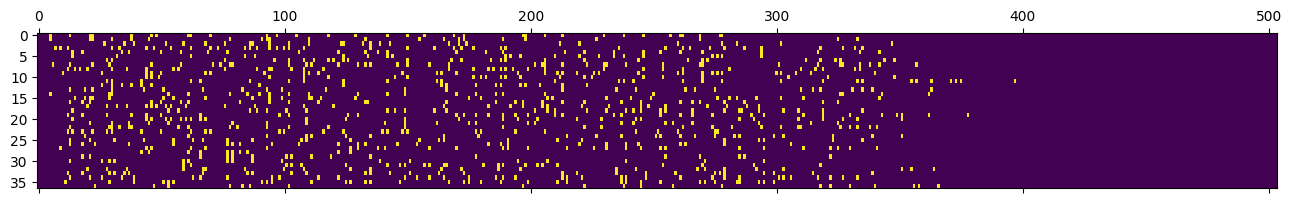

In [426]:
matshow(A_hs, aspect = 'auto')

Text(0, 0.5, '2-Wasserstein^2 Distance')

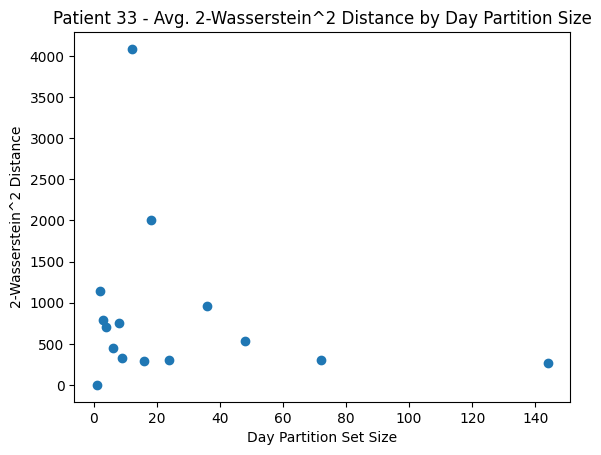

In [423]:
# plot performance against partition size
import matplotlib
from matplotlib import pyplot as plt

tst, err = zip(*sorted(zip(tst_partitions, error_part)))

plt.scatter(tst, err)
plt.title("Patient 33 - Avg. 2-Wasserstein^2 Distance by Day Partition Size")
plt.xlabel("Day Partition Set Size")
plt.ylabel("2-Wasserstein^2 Distance")

Text(0, 0.5, '2-Wasserstein^2 Distance')

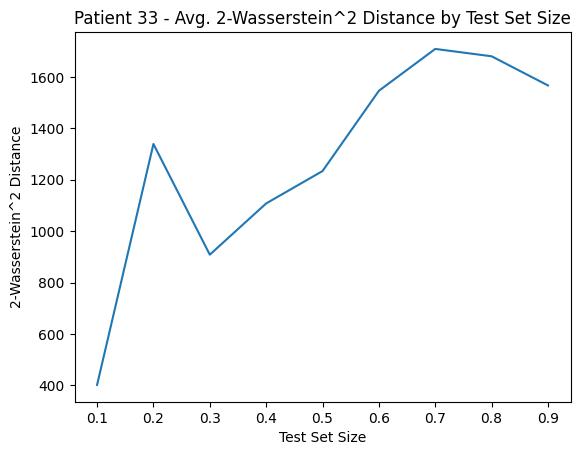

In [40]:
# plot perfomance aganst test set size
plt.plot(tst_size, error)
plt.title("Patient 33 - Avg. 2-Wasserstein^2 Distance by Test Set Size")
plt.xlabel("Test Set Size")
plt.ylabel("2-Wasserstein^2 Distance")



In [427]:
# row 33 is best performing with testset = 0.3, k = 5
#for i in range(1, 38):
#print("k = " + str(i))
test_w2_cv_heartsteps(M_hs, A_hs, testset_size = 0.3, k = 5, row = 33)


  0%|          | 0/50 [00:00<?, ?trial/s, best loss=?]

C:\Users\Caleb\AppData\Local\Temp\ipykernel_19552\1692393033.py:33: RuntimeWarning: Mean of empty slice
  w_2 = np.nanmean((Y_i - Y_js) ** 2, axis = -1)

C:\Users\Caleb\AppData\Local\Temp\ipykernel_19552\1692393033.py:70: RuntimeWarning: Mean of empty slice
  scores[cols] = np.nanmean(w2_scores, axis = 2)



100%|██████████| 50/50 [00:17<00:00,  2.80trial/s, best loss: 6692.699882685241]
Avg Wasserstein Error: 230.57069631657856


230.57069631657856

In [431]:
# select random sample of units
rng = np.random.default_rng()
sel_units = rng.choice(37, 4, replace = False)
sel_units


array([28,  3, 13,  2], dtype=int64)

In [436]:
# Wasserstein error computing neighbors with A = 1
tstset_size = []
avg_error = []
for j in np.linspace(0.1, 0.9, num=9):
  print("Test set size " + str(j))
  tstset_size.append(i)
  err = 0
  for i in sel_units:
    tst_partitions.append(i)
    err += test_w2_cv_heartsteps(M_hs, A_hs, testset_size = j, k = 5, row = i)
  avg_error.append(err / 4)



Test set size 0.1


C:\Users\Caleb\AppData\Local\Temp\ipykernel_19552\1692393033.py:33: RuntimeWarning: Mean of empty slice
  w_2 = np.nanmean((Y_i - Y_js) ** 2, axis = -1)
C:\Users\Caleb\AppData\Local\Temp\ipykernel_19552\1692393033.py:70: RuntimeWarning: Mean of empty slice
  scores[cols] = np.nanmean(w2_scores, axis = 2)


Avg Wasserstein Error: 2287.1761998685074
Avg Wasserstein Error: 10113.258488037538
Avg Wasserstein Error: 1480.1723336888313
Avg Wasserstein Error: 2567.2496381676265
Test set size 0.2
Avg Wasserstein Error: 4911.289467478972
Avg Wasserstein Error: 38661.45607307526
Avg Wasserstein Error: 2548.584332397404
Avg Wasserstein Error: 2900.9107068046083
Test set size 0.30000000000000004
Avg Wasserstein Error: 8970.249536115849
Avg Wasserstein Error: 23265.30406731295
Avg Wasserstein Error: 3963.2192615393355
Avg Wasserstein Error: 2703.0211744039952
Test set size 0.4
Avg Wasserstein Error: 14303.657595577688
Avg Wasserstein Error: 17509.531562337746
Avg Wasserstein Error: 5598.701823532187
Avg Wasserstein Error: 7746.434115588944
Test set size 0.5
Avg Wasserstein Error: 11582.045442364313
Avg Wasserstein Error: 13051.11463209793
Avg Wasserstein Error: 5723.897845972869
Avg Wasserstein Error: 6918.771469519611
Test set size 0.6
Avg Wasserstein Error: 3019.505224943186
Avg Wasserstein Error: 

In [446]:
# Wasserstein error computing neighbors with A = 0
tstset_size_A0 = []
avg_error_A0 = []
for j in np.linspace(0.1, 0.9, num=9):
  print("Test set size " + str(j))
  tstset_size_A0.append(j)
  err = 0
  for i in sel_units:
    err += test_w2_cv_heartsteps(M_hs, A_hs, testset_size = j, k = 5, row = i, negate_mask = True)
  avg_error_A0.append(err / 4)

Test set size 0.1


C:\Users\Caleb\AppData\Local\Temp\ipykernel_19552\3922195370.py:33: RuntimeWarning: Mean of empty slice
  w_2 = np.nanmean((Y_i - Y_js) ** 2, axis = -1)
C:\Users\Caleb\AppData\Local\Temp\ipykernel_19552\3922195370.py:70: RuntimeWarning: Mean of empty slice
  scores[cols] = np.nanmean(w2_scores, axis = 2)


Avg Wasserstein Error: 0.0
Avg Wasserstein Error: 0.0
Avg Wasserstein Error: 536.4444444444445
Avg Wasserstein Error: 1197.722222222222
Test set size 0.2
Avg Wasserstein Error: 0.0
Avg Wasserstein Error: 0.0
Avg Wasserstein Error: 747.3384691358025
Avg Wasserstein Error: 0.0
Test set size 0.30000000000000004
Avg Wasserstein Error: 0.0
Avg Wasserstein Error: 0.0
Avg Wasserstein Error: 0.0
Avg Wasserstein Error: 0.0
Test set size 0.4
Avg Wasserstein Error: 0.0
Avg Wasserstein Error: 0.0
Avg Wasserstein Error: 665.6288580246915
Avg Wasserstein Error: 0.0
Test set size 0.5
Avg Wasserstein Error: 0.0
Avg Wasserstein Error: 0.0
Avg Wasserstein Error: 295.5160968660969
Avg Wasserstein Error: 0.0
Test set size 0.6
Avg Wasserstein Error: 0.0
Avg Wasserstein Error: 0.0
Avg Wasserstein Error: 0.0
Avg Wasserstein Error: 0.0
Test set size 0.7000000000000001
Avg Wasserstein Error: 0.0
Avg Wasserstein Error: 0.0
Avg Wasserstein Error: 159.52160493827162
Avg Wasserstein Error: 6.459064327485381
Test s

## Unit-Time Specfic Experiments

In [83]:
import cross_validate_dnn as cv_dnn
import dnn
# set up
A_hs = np.load("heartsteps_mask.npy")
M_hs = np.load("heartsteps_data.npy")

# required for Wasserstein
M_hs = np.sort(M_hs, axis = -1)
M_hs = M_hs[:, :, :, None]

error_mmd_sqkernel = np.zeros([N, T])
error_mmd_expkernel = np.zeros([N, T])
error_wasserstein = np.zeros([N, T])

# truncate the data as most users have had 40 days
M_hs = M_hs[:, 0:200]
A_hs = A_hs[:, 0:200]

N, T, n, d = M_hs.shape


In [97]:
import matplotlib.pyplot as plt
import matplotlib as mpl

plt.rc('font', family='serif')
plt.rc('text', usetex=False)
plt.rc('axes', axisbelow=True)
label_size = 15
mpl.rcParams['xtick.labelsize'] = label_size 
mpl.rcParams['ytick.labelsize'] = label_size 
mpl.rcParams['axes.labelsize'] = label_size
mpl.rcParams['axes.titlesize'] = label_size
mpl.rcParams['figure.titlesize'] = label_size
mpl.rcParams['lines.markersize'] = label_size
mpl.rcParams['grid.linewidth'] = 2.5
mpl.rcParams['legend.fontsize'] = label_size


lss = ['--',  ':', '-.', '-', '--', '-.', ':', '-', '--', '-.', ':', '-']
mss = ['x', 'o', '>', 's', 'D', '>', 'D', '>', 's', 'o', 'D']


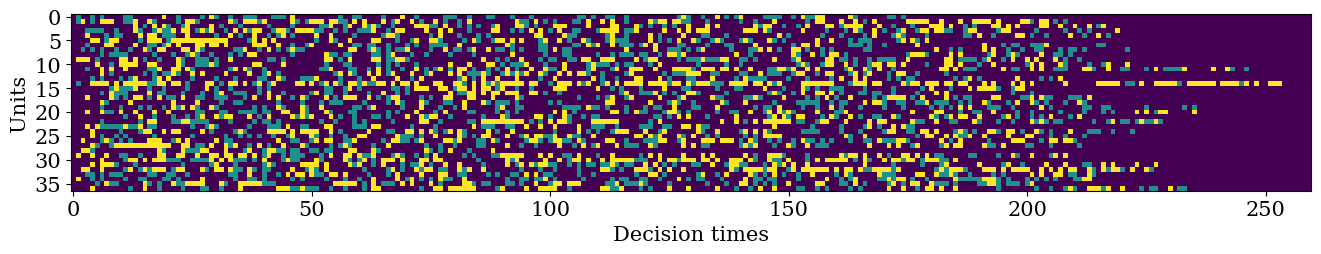

In [112]:
A_hs = np.load("heartsteps_mask.npy")

plt.matshow(A_hs, aspect = 'auto')
plt.ylabel("Units")
plt.xlabel("Decision times")
plt.gca().xaxis.tick_bottom()
plt.savefig("HS_mask_tight.pdf", bbox_inches = "tight")

In [82]:
# use the truncated pys?
M_hs.shape

(37, 200, 12, 1)

In [49]:
diffs = dnn.get_col_differences(M_hs, A_hs, "mmd", "square")

10306
14257


c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn.py:230: RuntimeWarning: Mean of empty slice
  # since MMD_hat is estimate, could be negative. if negative, assume that the MMD distance is 0


In [71]:
diffs = diffs[(diffs != 0) & (~np.isinf(diffs))]
np.nanmedian(diffs)

2596833.996212121

In [48]:
np.nanmedian(diffs[~np.isinf(diffs)])
np.sum(diffs[~np.isnan(diffs)] == 0.0)

24327

In [90]:
# for each row, search for eta, estimate the row
split_A = np.split(A_hs, 2, axis = 1)
split_M = np.split(M_hs, 2, axis = 1)

width = len(A_hs[0])
ws2_estimates = np.full([N, T, n], np.nan)

mmd_estimates_exp = [None] * N
mmd_estimates_sq = [None] * N

for i in range(len(A_hs)):
  print("User " + str(i))
  # sample split
  dist_A = A_hs.copy()
  dist_A[i] = 0

  wasserstein_diffs = dnn.get_col_differences(M_hs, dist_A, metric = "wasserstein2", kernel = None)
  mmd_exp_diffs, mmd_sq_diffs = dnn.get_col_differences_all_kernels(M_hs, dist_A, metric = "mmd", kernel = "")

  s_ws2 = np.split(wasserstein_diffs, 2, axis = 0)
  diffs_ws2_front = np.split(s_ws2[0], 2, axis = 1)[0]
  diffs_ws2_back = np.split(s_ws2[1], 2, axis = 1)[1]

  s_mmd_exp = np.split(mmd_exp_diffs, 2, axis = 0)
  diffs_mmd_exp_front = np.split(s_mmd_exp[0], 2, axis = 1)[0]
  diffs_mmd_exp_back = np.split(s_mmd_exp[1], 2, axis = 1)[1]

  s_mmd_sq = np.split(mmd_sq_diffs, 2, axis = 0)
  diffs_mmd_sq_front = np.split(s_mmd_sq[0], 2, axis = 1)[0]
  diffs_mmd_sq_back = np.split(s_mmd_sq[1], 2, axis = 1)[1]

  
  # TWO eta searches per row, one using the front half
  # the other using the back half 

  front_A_hs = split_A[0]
  back_A_hs = split_A[1]
  front_M_hs = split_M[0]
  back_M_hs = split_M[1]
  eta_star_ws2_front, _ = cv_dnn.search_eta(front_M_hs, front_A_hs, 5, i, 
                                         diffs_ws2_front, dnn.estimate_row, 
                                         metric="wasserstein2", 
                                         range_min = 0, range_max = 50000)
  eta_star_ws2_back, _ = cv_dnn.search_eta(back_M_hs, back_A_hs, 5, i,
                                        diffs_ws2_back, dnn.estimate_row,
                                        metric = "wasserstein2",
                                        range_min = 0, range_max = 50000)
  eta_star_mmd_exp_front, _ = cv_dnn.search_eta(front_M_hs, front_A_hs, 5, i, 
                                         diffs_mmd_exp_front, dnn.estimate_row, 
                                         metric="mmd", kernel = "exponential", 
                                         range_min = 0, range_max = 0.3)
  eta_star_mmd_exp_back, _ = cv_dnn.search_eta(back_M_hs, back_A_hs, 5, i,
                                        diffs_mmd_exp_back, dnn.estimate_row,
                                        metric = "mmd", kernel = "exponential",
                                        range_min = 0, range_max = 0.3)
  eta_star_mmd_sq_front, _ = cv_dnn.search_eta(front_M_hs, front_A_hs, 5, i, 
                                         diffs_mmd_sq_front, dnn.estimate_row, 
                                         metric="mmd", kernel = "square", 
                                         range_min = 0, range_max = 3000000)
  eta_star_mmd_sq_back,_ = cv_dnn.search_eta(back_M_hs, back_A_hs, 5, i,
                                        diffs_mmd_sq_back, dnn.estimate_row,
                                        metric = "mmd", kernel = "square",
                                        range_min = 0, range_max = 3000000)
  # estimate first half using eta from second
  test_inds = np.nonzero(A_hs[i] == 1)[0]
  front_test_inds = test_inds[test_inds < (width / 2)]
  back_test_inds = test_inds[test_inds >= (width / 2)]

  print("Estimating unit " + str(i))

  estimate_front_ws2 = dnn.estimate_row(M_hs, A_hs, i, front_test_inds, 
                                        wasserstein_diffs, eta_star_ws2_back, 
                                        "wasserstein2")[:T // 2]
  estimate_back_ws2 = dnn.estimate_row(M_hs, A_hs, i, back_test_inds, 
                                        wasserstein_diffs, eta_star_ws2_front, 
                                        "wasserstein2")[T // 2 : ]
  estimate_front_mmd_exp = dnn.estimate_row(M_hs, A_hs, i, front_test_inds,
                                            mmd_exp_diffs, eta_star_mmd_exp_back,
                                            "mmd")[:T // 2 ]
  estimate_back_mmd_exp = dnn.estimate_row(M_hs, A_hs, i, back_test_inds,
                                            mmd_exp_diffs, eta_star_mmd_exp_front,
                                            "mmd")[T // 2 :]
  estimate_front_mmd_sq = dnn.estimate_row(M_hs, A_hs, i, front_test_inds,
                                            mmd_sq_diffs, eta_star_mmd_sq_back,
                                            "mmd")[:T // 2]
  estimate_back_mmd_sq = dnn.estimate_row(M_hs, A_hs, i, back_test_inds,
                                            mmd_sq_diffs, eta_star_mmd_sq_front,
                                            "mmd")[T // 2 :]
  
  # concat estimates together
  est_row_ws2 = np.concatenate((estimate_front_ws2, estimate_back_ws2), axis = 0)
  est_row_mmd_exp = estimate_front_mmd_exp + estimate_back_mmd_exp
  est_row_mmd_sq = estimate_front_mmd_sq + estimate_back_mmd_sq

  ws2_estimates[i] = est_row_ws2
  mmd_estimates_exp[i] = est_row_mmd_exp
  mmd_estimates_sq[i] = est_row_mmd_sq


  

  
  
  

User 0
100%|██████████| 200/200 [00:01<00:00, 159.89trial/s, best loss: 201393321.04113135]
Estimating unit 0
User 1
100%|██████████| 200/200 [00:00<00:00, 242.16trial/s, best loss: 1469369587.4481645]
Estimating unit 1
User 2
100%|██████████| 200/200 [00:01<00:00, 186.59trial/s, best loss: 736493119.8540841]
Estimating unit 2
User 3
100%|██████████| 200/200 [00:01<00:00, 167.49trial/s, best loss: 202655436.83841836]
Estimating unit 3
User 4
100%|██████████| 200/200 [00:01<00:00, 179.25trial/s, best loss: 323814972.5404154]
Estimating unit 4
User 5
100%|██████████| 200/200 [00:01<00:00, 176.70trial/s, best loss: 3384695547.63339] 
Estimating unit 5
User 6
100%|██████████| 200/200 [00:01<00:00, 153.63trial/s, best loss: 111477839.47441849]
Estimating unit 6
User 7
100%|██████████| 200/200 [00:01<00:00, 177.11trial/s, best loss: 327814684.02138513]
Estimating unit 7
User 8
100%|██████████| 200/200 [00:01<00:00, 149.86trial/s, best loss: 981561535.0000778]
Estimating unit 8
User 9
100%|██

In [144]:
len(mmd_estimates_exp[0])

200

In [122]:
M_hs_anly = M_hs.copy()
M_hs_anly.shape


(37, 200, 12, 1)

In [121]:
ws2_estimate_sorted = np.sort(ws2_estimates, axis = 2)
ws2_estimate_sorted = ws2_estimate_sorted[:,:,:,None]
ws2_estimate_sorted.shape

(37, 200, 12, 1)

In [123]:
wasserstein_error_M_hs = np.full([N, T], np.nan)

for i in range(N):
  for j in range(T):
    wasserstein_error_M_hs[i, j] = dnn.avg_wasserstein2_dist(ws2_estimate_sorted[i, j],
                                                             M_hs_anly[i, j])
  

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn.py:183: RuntimeWarning: Mean of empty slice
  return np.nanmean((np.nanmean((Y_i - Y_j)**2, axis = 1)), axis = 0)


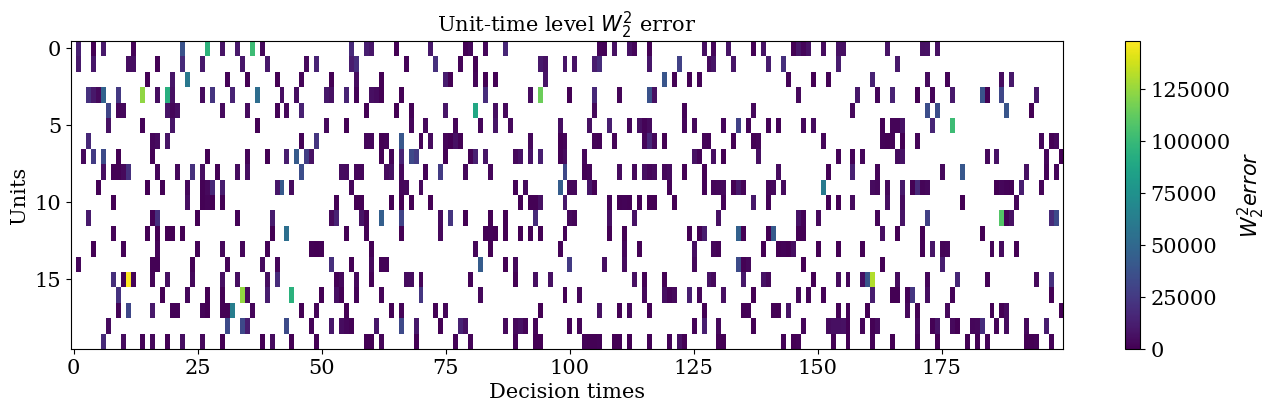

In [194]:
fig, ax = plt.subplots(figsize=(16, 4))

pos = ax.imshow(wasserstein_error_M_hs[0:20], aspect = 'auto')
fig.colorbar(pos, ax = ax, label = "$W_2^2 error$")

ax.set_ylabel("Units")
ax.set_xlabel("Decision times")
ax.xaxis.tick_bottom()
ax.set_title("Unit-time level $W^2_2$ error")
plt.savefig("ws2_matrix_err.pdf", bbox_inches = "tight")


In [168]:
all_errors = wasserstein_error_M_hs[~np.isnan(wasserstein_error_M_hs)]

zero_inds = np.nonzero(wasserstein_error_M_hs == 0.0)
M_hs[zero_inds]

array([[[0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.]],

       [[0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.]],

       [[0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.]],

       [[0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.]],

       [[0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.]],

       [[0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0

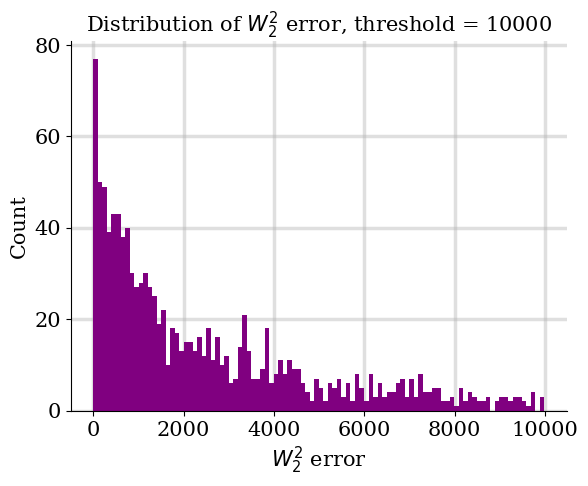

In [205]:
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(True, alpha=0.4)
plt.hist(all_errors[all_errors < 10000], bins = 100, color="purple")
plt.title("Distribution of $W_2^2$ error, threshold = 10000")
plt.xlabel("$W^2_2$ error")
plt.ylabel("Count")
plt.savefig("ws2_err_dist.pdf", bbox_inches = "tight")

In [148]:
mmd_error_M_hs = np.full([N, T], np.nan)

for i in range(N):
  for j in range(T):
    est = mmd_estimates_exp[i][j]
    truth = M_hs_anly[i, j]
    if est is None:
      mmd_error_M_hs[i, j] = np.nan
    else:
      mmd_error_M_hs[i, j] = dnn.sqmmd_est2(est, truth, kernel = "exponential")

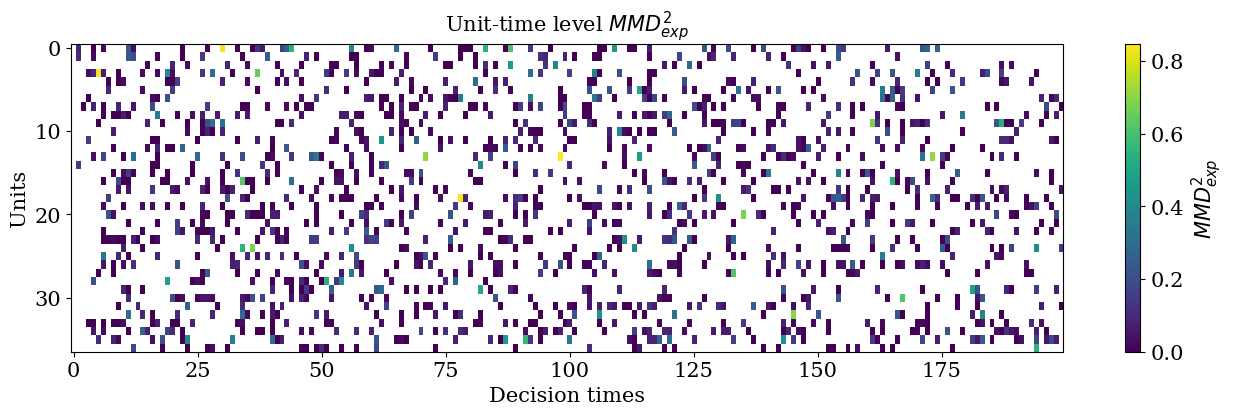

In [207]:
fig, ax = plt.subplots(figsize=(16, 4))

pos = ax.imshow(mmd_error_M_hs, aspect = 'auto')
fig.colorbar(pos, ax = ax, label = "$MMD_{exp}^2$")

ax.set_ylabel("Units")
ax.set_xlabel("Decision times")
ax.xaxis.tick_bottom()
ax.set_title("Unit-time level $MMD_{exp}^2$")
plt.savefig("mmd_exp_matrix_err.pdf", bbox_inches = "tight")

(array([1074.,  209.,  100.,   44.,   22.,   11.,   10.,    5.,    6.,
           4.]),
 array([0.        , 0.08478869, 0.16957738, 0.25436607, 0.33915476,
        0.42394345, 0.50873214, 0.59352082, 0.67830951, 0.7630982 ,
        0.84788689]),
 <BarContainer object of 10 artists>)

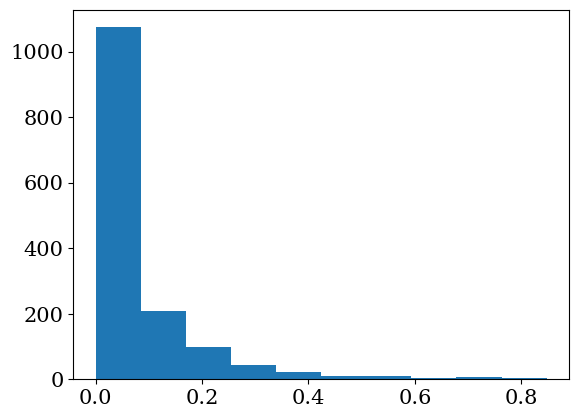

In [151]:
plt.hist(mmd_error_M_hs[~np.isnan(mmd_error_M_hs)])

In [176]:
rows, cols = np.nonzero(mmd_error_M_hs == 0.0)

for k in range(len(rows) // 2 ):
  i = rows[k]
  j = cols[k]
  print("pair")
  print(M_hs[i, j])
  print(mmd_estimates_exp[i][j])


pair
[[  0.]
 [  0.]
 [  0.]
 [  0.]
 [  0.]
 [  0.]
 [ 34.]
 [ 40.]
 [ 79.]
 [140.]
 [162.]
 [195.]]
[[  0.]
 [ 16.]
 [ 21.]
 [ 35.]
 [ 45.]
 [ 53.]
 [ 64.]
 [ 78.]
 [ 81.]
 [ 98.]
 [102.]
 [114.]
 [  0.]
 [  0.]
 [  0.]
 [  0.]
 [  0.]
 [  0.]
 [  0.]
 [  0.]
 [  0.]
 [  0.]
 [  0.]
 [  0.]]
pair
[[  0.]
 [ 23.]
 [ 95.]
 [184.]
 [226.]
 [242.]
 [317.]
 [331.]
 [384.]
 [385.]
 [434.]
 [458.]]
[[  0.]
 [ 16.]
 [ 21.]
 [ 35.]
 [ 45.]
 [ 53.]
 [ 64.]
 [ 78.]
 [ 81.]
 [ 98.]
 [102.]
 [114.]]
pair
[[  0.]
 [  0.]
 [  0.]
 [  0.]
 [  0.]
 [ 21.]
 [107.]
 [412.]
 [556.]
 [575.]
 [577.]
 [582.]]
[[  0.]
 [  0.]
 [  0.]
 [  0.]
 [  0.]
 [  0.]
 [ 34.]
 [ 40.]
 [ 79.]
 [140.]
 [162.]
 [195.]
 [  0.]
 [ 16.]
 [ 21.]
 [ 35.]
 [ 45.]
 [ 53.]
 [ 64.]
 [ 78.]
 [ 81.]
 [ 98.]
 [102.]
 [114.]
 [  0.]
 [  0.]
 [  0.]
 [  0.]
 [  0.]
 [ 30.]
 [ 50.]
 [ 58.]
 [ 75.]
 [165.]
 [217.]
 [347.]]
pair
[[  0.]
 [  0.]
 [  0.]
 [  0.]
 [  0.]
 [ 55.]
 [ 72.]
 [451.]
 [550.]
 [584.]
 [587.]
 [595.]]
[[  0.]
 [ 35

In [152]:
mmd_error_M_hs_sq = np.full([N, T], np.nan)

for i in range(N):
  for j in range(T):
    est = mmd_estimates_sq[i][j]
    truth = M_hs_anly[i, j]
    if est is None:
      mmd_error_M_hs_sq[i, j] = np.nan
    else:
      mmd_error_M_hs_sq[i, j] = dnn.sqmmd_est2(est, truth, kernel = "square")


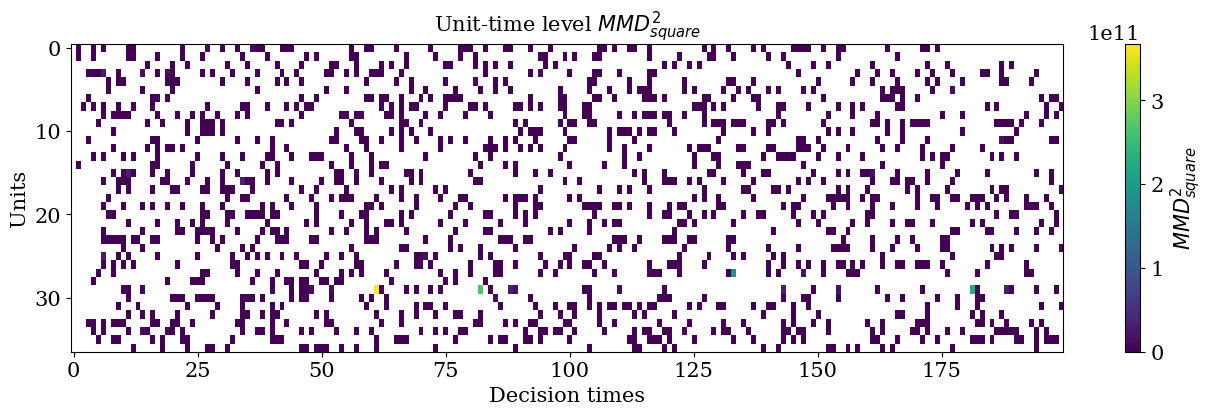

In [209]:
fig, ax = plt.subplots(figsize=(16, 4))

pos = ax.imshow(mmd_error_M_hs_sq, aspect = 'auto')
fig.colorbar(pos, ax = ax, label = "$MMD_{square}^2$")


ax.set_ylabel("Units")
ax.set_xlabel("Decision times")
ax.xaxis.tick_bottom()
ax.set_title("Unit-time level $MMD_{square}^2$")
plt.savefig("mmd_sq_matrix_err.pdf", bbox_inches = "tight")

(array([328.,   1.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   1.]),
 array([    0.        ,  1783.09009668,  3566.18019337,  5349.27029005,
         7132.36038673,  8915.45048341, 10698.5405801 , 12481.63067678,
        14264.72077346, 16047.81087015, 17830.90096683]),
 <BarContainer object of 10 artists>)

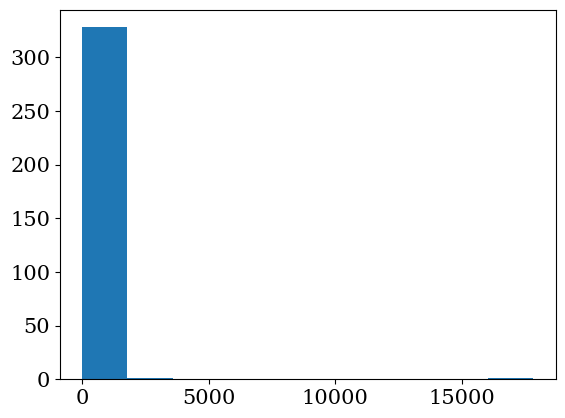

In [164]:
errs = mmd_error_M_hs_sq[~np.isnan(mmd_error_M_hs_sq)]
plt.hist(errs[errs < 20000])

In [181]:
import scipy
from scipy.stats import kstest 
kstest(np.array([0, 1, 2]), np.array([3, 4, 5])).statistic

1.0

In [182]:
ks_error_ws2_estimates = np.full([N, T], np.nan)
for i in range(N):
  for j in range(T):
    ks_error_ws2_estimates[i, j] = kstest(ws2_estimate_sorted[i, j], 
                                          M_hs_anly[i, j]).statistic


C:\Users\Caleb\AppData\Local\Temp\ipykernel_20492\4280863373.py:4: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  ks_error_ws2_estimates[i, j] = kstest(ws2_estimate_sorted[i, j],


In [186]:
ks_mmd_error_exp= np.full([N, T], np.nan)
for i in range(N):
  for j in range(T):
    est = mmd_estimates_exp[i][j]
    truth = M_hs_anly[i, j]
    if est is None:
      ks_mmd_error_exp[i, j] = np.nan
    else:
      ks_mmd_error_exp[i, j] = kstest(est, truth).statistic

C:\Users\Caleb\AppData\Local\Temp\ipykernel_20492\455578326.py:9: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  ks_mmd_error_exp[i, j] = kstest(est, truth).statistic


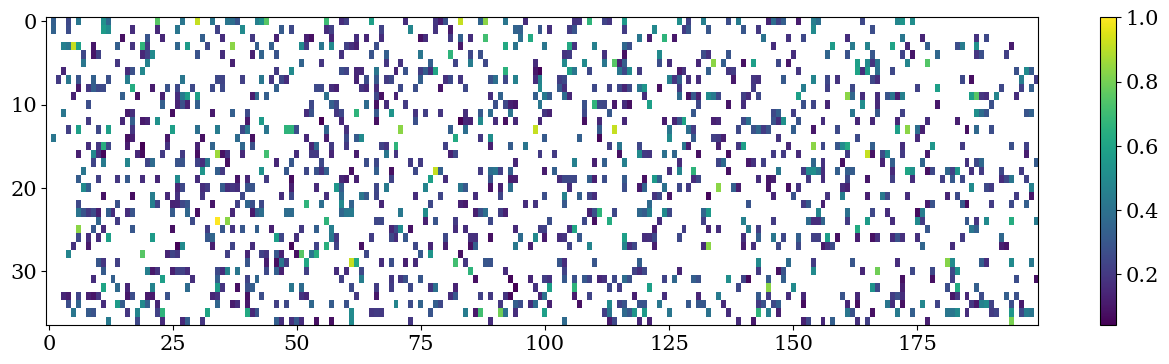

In [188]:
fig, ax = plt.subplots(figsize=(16, 4))

pos = ax.imshow(ks_mmd_error_exp, aspect = 'auto')
fig.colorbar(pos, ax = ax)

In [189]:
ks_mmd_error_sq= np.full([N, T], np.nan)
for i in range(N):
  for j in range(T):
    est = mmd_estimates_sq[i][j]
    truth = M_hs_anly[i, j]
    if est is None:
      ks_mmd_error_sq[i, j] = np.nan
    else:
      ks_mmd_error_sq[i, j] = kstest(est, truth).statistic

C:\Users\Caleb\AppData\Local\Temp\ipykernel_20492\4171140227.py:9: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  ks_mmd_error_sq[i, j] = kstest(est, truth).statistic


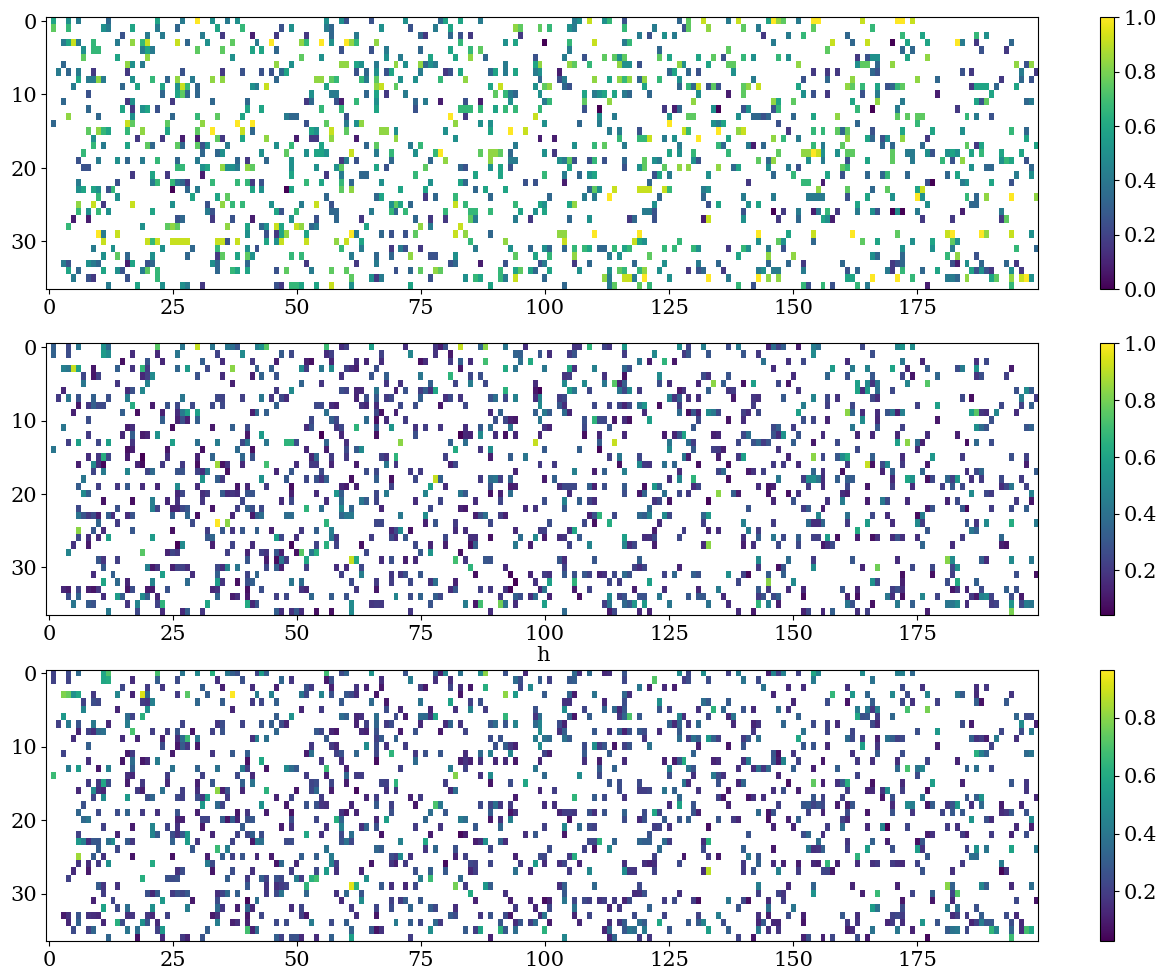

In [213]:
fig, (ax1, ax2, ax3) = plt.subplots(figsize=(16, 12), nrows = 3)


pos1 = ax1.imshow(ks_error_ws2_estimates, aspect = 'auto')
pos2 = ax2.imshow(ks_mmd_error_exp, aspect = 'auto')
pos3 = ax3.imshow(ks_mmd_error_sq, aspect = 'auto')

fig.colorbar(pos1, ax = ax1)
fig.colorbar(pos2, ax = ax2, label = "2-sample Kolmogorov-Smirnov test statistic")
fig.colorbar(pos3, ax = ax3)

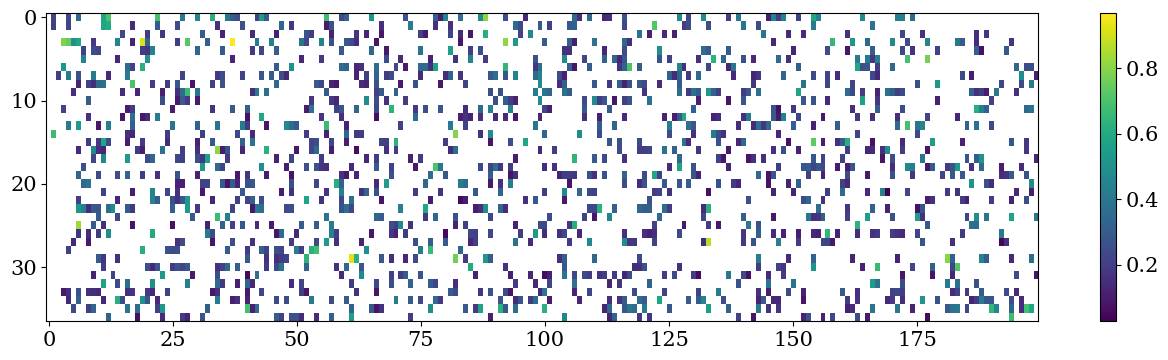

In [190]:
fig, ax = plt.subplots(figsize=(16, 4))

pos = ax.imshow(ks_mmd_error_sq, aspect = 'auto')
fig.colorbar(pos, ax = ax)

In [89]:
eta_star_ws2_back, _ = cv_dnn.search_eta(back_M_hs, back_A_hs, 5, 28,
                                        diffs_ws2_back, dnn.estimate_row,
                                        metric = "wasserstein2",
                                        range_min = 0, range_max = 50000)

100%|██████████| 200/200 [00:00<00:00, 222.24trial/s, best loss: inf]
